# MorphHema-NET · YOLO26 per-cell branch · Explainability study
**EigenCAM (stride-4, stride-8, multi-layer), Pseudo-EigenCAM, D-RISE and GradientSHAP, with a quantitative comparison and a detection-improvement test**

**Before running:** Settings → Accelerator **GPU (T4 or P100)**, Internet **ON**. Both Drive files must be shared as *Anyone with the link*. Then *Run all*.

What the notebook does:
1. Downloads `anemia_500.zip` (AneRBC records), `Normochromic_pallor_mil_results.zip` and `yolo26s.zip`.
2. Downloads `yolo26s.zip` and uses the **fine-tuned YOLO26 per-cell detector** in it. Files that are not detectors (e.g. the ConvNeXt-MIL checkpoint `best_convnext_attention_mil.pt`) or COCO-pretrained weights are skipped automatically. Training (per-cell pallor labels, 33% / 50%) runs only if no fine-tuned detector is found.
3. Explains the detector with each method in its own section.
4. Scores every method on the same detections (deletion AUC, pointing game, energy-in-box) and shows the best one.
5. Tests whether EigenCAM can improve detection on held-out fields.

All figures are displayed inline **and** saved at **300 dpi** in `/kaggle/working/xai_outputs`.

## 1. Setup

In [1]:
%pip install -q -U ultralytics gdown

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, random, shutil, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
import gdown
from ultralytics import YOLO
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

CFG = dict(
    ANEMIA_ZIP_ID="1wzpJs8wY9b59f4KGUPIGOiAnfcqLo4j4",    # anemia_500.zip
    RESULTS_ZIP_ID="1xTIQRHmeh4-dokjhyW7k5CrnfecYIcAO",   # Normochromic_pallor_mil_results.zip
    YOLO_ZIP_ID="1mMqZ7-Kdvkxpwz3YOjtnSm5ROs60UEe5",      # yolo26s.zip (fine-tuned per-cell detector)
    WORK="/kaggle/working" if os.path.isdir("/kaggle/working") else "./work",
    WEIGHTS=None,            # path to fine-tuned YOLO26 weights; None = use yolo26s.zip (else train)
    IMAGE_ROLE="rgb",        # images to use: "rgb" (RGB-segmented) or "orig"
    CELLS_ARE_BLACK=True,    # AneRBC binary masks: RBC black, background white
    IMGSZ=640, CONF=0.447, SEED=42,
    # YOLO26 training (only if no detector weights exist)
    TRAIN_MODEL="yolo26s.pt", EPOCHS=50, BATCH=16, VAL_FRACTION=0.2,
    T_MILD=33.0, T_SEVERE=50.0,
    # explainability
    XAI_FIELDS=6, TARGETS_PER_FIELD=6,
    DRISE_MASKS=2000, DRISE_GRID=16, DRISE_P=0.5, PRED_BATCH=32,
    GSHAP_SAMPLES=32, GSHAP_BATCH=8, GSHAP_NOISE=0.05, GSHAP_SMOOTH=1.5,
    DEL_STEPS=10,
    # detection-improvement test
    N_EVAL=300, LAMBDAS=[0.1, 0.2, 0.3, 0.4, 0.5], BETAS=[0.25, 0.5, 1.0], N_BOOT=300,
)

WORK = Path(CFG["WORK"]); WORK.mkdir(parents=True, exist_ok=True)
OUT = WORK / "xai_outputs"; OUT.mkdir(exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
GPU = 0 if DEV == "cuda" else "cpu"
S = CFG["IMGSZ"]; DPI = 300
CLASS_COLORS = {0: (0, 200, 0), 1: (255, 200, 0), 2: (230, 0, 0)}
CLASS_NAMES = {0: "normochromic", 1: "mild hypochromic", 2: "severely hypochromic"}
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])

def save_show(fig, name):
    # save at 300 dpi and display inline
    fig.savefig(OUT / name, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Device:", DEV)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cuda


## 2. Download and unzip the data

In [3]:
def fetch(file_id, name):
    zp, dst = WORK / name, WORK / Path(name).stem
    if dst.exists() and any(dst.rglob("*")):
        print("Already extracted:", dst)
        return dst
    if not zp.exists():
        gdown.download(f"https://drive.google.com/uc?id={file_id}", str(zp), quiet=False)
    if not zp.exists() or zp.stat().st_size < 1000:
        raise RuntimeError(f"Download of {name} failed. Share the Drive file as 'Anyone with the link'.")
    with zipfile.ZipFile(zp) as z:
        z.extractall(dst)
    return dst

DATA_DIR = fetch(CFG["ANEMIA_ZIP_ID"], "anemia_500.zip")
RES_DIR = fetch(CFG["RESULTS_ZIP_ID"], "Normochromic_pallor_mil_results.zip")
YOLO_DIR = fetch(CFG["YOLO_ZIP_ID"], "yolo26s.zip")

Downloading...
From (original): https://drive.google.com/uc?id=1wzpJs8wY9b59f4KGUPIGOiAnfcqLo4j4
From (redirected): https://drive.google.com/uc?id=1wzpJs8wY9b59f4KGUPIGOiAnfcqLo4j4&confirm=t&uuid=a751aded-20b8-4ad4-8848-69eed355277f
To: /kaggle/working/anemia_500.zip
100%|██████████| 1.98G/1.98G [00:15<00:00, 128MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1xTIQRHmeh4-dokjhyW7k5CrnfecYIcAO
From (redirected): https://drive.google.com/uc?id=1xTIQRHmeh4-dokjhyW7k5CrnfecYIcAO&confirm=t&uuid=fd504d7c-5708-425c-aad2-18d3ed307330
To: /kaggle/working/Normochromic_pallor_mil_results.zip
100%|██████████| 127M/127M [00:01<00:00, 88.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1mMqZ7-Kdvkxpwz3YOjtnSm5ROs60UEe5
To: /kaggle/working/yolo26s.zip
100%|██████████| 20.4M/20.4M [00:00<00:00, 42.7MB/s]


In [4]:
def summarize(root, depth=3):
    rows = {}
    for p in root.rglob("*"):
        if p.is_file():
            rel = p.relative_to(root).parts
            key = "/".join(rel[:min(depth, len(rel) - 1)]) or "."
            ext = p.suffix.lower() or "(none)"
            rows.setdefault(key, {}).setdefault(ext, 0)
            rows[key][ext] += 1
    return pd.DataFrame([dict(folder=k, **v) for k, v in sorted(rows.items())]).fillna(0)

display(Markdown("**Anemia data folders**")); display(summarize(DATA_DIR))
display(Markdown("**Results zip folders**")); display(summarize(RES_DIR))
display(Markdown("**YOLO26 zip folders**")); display(summarize(YOLO_DIR))

**Anemia data folders**

,folder,.csv,.png
0,anemia_500,2.0,0.0
1,anemia_500/Binary_Segmented,0.0,6000.0
2,anemia_500/Original_Images,0.0,6000.0
3,anemia_500/RGB_Segmented,0.0,6000.0


**Results zip folders**

,folder,.json,.png,.pkl,.pt,.csv,.txt
0,.,1.0,0.0,0.0,0.0,0.0,0.0
1,figures,0.0,18.0,0.0,0.0,0.0,0.0
2,models,0.0,0.0,2.0,1.0,0.0,0.0
3,tables,1.0,0.0,0.0,0.0,6.0,2.0


**YOLO26 zip folders**

,folder,(none),.pkl
0,best,4,1.0
1,best/.data,1,0.0
2,best/data,712,0.0


## 3. Discover images, masks and pallor tables

In [5]:
def role_of(p):
    s = str(p).lower()
    if "binary" in s or "mask" in s: return "mask"
    if "rgb" in s: return "rgb"
    if "original" in s or "orig" in s: return "orig"
    return "other"

def norm_key(p):
    k = Path(p).stem.lower()
    k = re.sub(r"(_|-)?(mask|binary|bin|rgb|seg(mented)?|original|orig|gt)(_|-)?", "_", k)
    return re.sub(r"_+", "_", k).strip("_")

def discover(root):
    groups = {}
    for p in root.rglob("*"):
        if p.suffix.lower() not in IMG_EXT: continue
        if {"labels", "runs", "xai_outputs"} & {x.lower() for x in p.parts}: continue
        groups.setdefault(norm_key(p), {}).setdefault(role_of(p), p)
    return groups

def pick_image(g):
    order = ["rgb", "orig", "other"] if CFG["IMAGE_ROLE"] == "rgb" else ["orig", "rgb", "other"]
    return next((g[r] for r in order if r in g), None)

def read_rgb(p):
    return cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)

GROUPS = discover(DATA_DIR)
print(f"{len(GROUPS)} image groups")
print(pd.Series([r for g in GROUPS.values() for r in g]).value_counts().to_string())

PALLOR = {}
for csv in RES_DIR.rglob("*.csv"):
    try:
        df = pd.read_csv(csv)
    except Exception:
        continue
    cols = {c.lower(): c for c in df.columns}
    fcol = next((cols[c] for c in cols if any(k in c for k in ("file", "image", "patch", "path", "name"))), None)
    rcol = next((cols[c] for c in cols if any(k in c for k in ("r_final", "rfinal", "pallor"))), None)
    if fcol is None or rcol is None: continue
    for f_, r_ in zip(df[fcol], df[rcol]):
        try: PALLOR[norm_key(str(f_))] = float(r_)
        except Exception: pass
print(f"Pallor ratios loaded for {len(PALLOR)} patches")

6000 image groups
mask    6000
rgb     6000
orig    6000
Pallor ratios loaded for 12 patches


## 4. Per-cell pallor labels (used only if a detector must be trained)

In [6]:
def cells_from_mask(mask_gray):
    fg = mask_gray < 128 if CFG["CELLS_ARE_BLACK"] else mask_gray >= 128
    fg = ndi.binary_fill_holes(ndi.binary_opening(fg, iterations=1))
    return ndi.label(fg)

def lightness(rgb):
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[..., 0].astype(np.float32) * 100.0 / 255.0

def cell_pallor(L, cell):
    # central-pallor ratio of one cell: 0.70 * width term + 0.30 * area term
    dist = ndi.distance_transform_edt(np.pad(cell, 1))[1:-1, 1:-1]
    if dist.max() < 2: return None
    vals = L[cell]
    pale = (dist >= 0.30 * dist.max()) & (L > np.median(vals) + 0.5 * vals.std())
    cy = int(round(np.nonzero(cell)[0].mean()))
    cw = cell[cy].sum()
    if cw == 0: return None
    r_w = 100.0 * pale[cy].sum() / cw
    r_a = 100.0 * np.sqrt(pale.sum() / max(cell.sum(), 1))
    return float(np.clip(0.70 * r_w + 0.30 * r_a, 0, 100))

def per_cell_labels(rgb, mask_gray):
    if mask_gray.shape != rgb.shape[:2]:
        mask_gray = cv2.resize(mask_gray, rgb.shape[1::-1], interpolation=cv2.INTER_NEAREST)
    lab, _ = cells_from_mask(mask_gray)
    L = lightness(rgb)
    boxes, cls = [], []
    for i, sl in enumerate(ndi.find_objects(lab), 1):
        if sl is None: continue
        cell = lab[sl] == i
        if cell.sum() < 30: continue
        r = cell_pallor(L[sl], cell)
        if r is None: continue
        boxes.append([sl[1].start, sl[0].start, sl[1].stop, sl[0].stop])
        cls.append(0 if r <= CFG["T_MILD"] else 1 if r <= CFG["T_SEVERE"] else 2)
    return np.array(boxes, float).reshape(-1, 4), np.array(cls, int)

def record_id(key):
    m = re.findall(r"\d+", key)
    return m[0] if m else key

def build_yolo_dataset():
    ds = WORK / "yolo_ds"; y = ds / "data.yaml"
    if y.exists(): return y
    zl = [d for r in (YOLO_DIR, RES_DIR) for d in r.rglob("labels") if d.is_dir() and any(d.rglob("*.txt"))]
    zy = [y_ for r in (YOLO_DIR, RES_DIR) for y_ in r.rglob("*.yaml") if "args" not in y_.name]
    if zl and zy:
        print("Using YOLO dataset from the results zip:", zy[0]); return zy[0]
    keys = [k for k, g in GROUPS.items() if "mask" in g and pick_image(g) is not None]
    recs = sorted({record_id(k) for k in keys}); random.Random(CFG["SEED"]).shuffle(recs)
    val_recs = set(recs[:max(1, int(len(recs) * CFG["VAL_FRACTION"]))])
    print(f"Building YOLO dataset: {len(keys)} fields from {len(recs)} records ({len(val_recs)} records for validation)")
    for s_ in ("train", "val"):
        (ds / "images" / s_).mkdir(parents=True, exist_ok=True)
        (ds / "labels" / s_).mkdir(parents=True, exist_ok=True)
    for n, k in enumerate(keys):
        g = GROUPS[k]; img = pick_image(g); rgb = read_rgb(img)
        b, c = per_cell_labels(rgb, cv2.imread(str(g["mask"]), cv2.IMREAD_GRAYSCALE))
        H, W = rgb.shape[:2]
        split = "val" if record_id(k) in val_recs else "train"
        shutil.copy(img, ds / "images" / split / f"{k}{img.suffix}")
        lines = [f"{ci} {(x0+x1)/2/W:.6f} {(y0+y1)/2/H:.6f} {(x1-x0)/W:.6f} {(y1-y0)/H:.6f}"
                 for (x0, y0, x1, y1), ci in zip(b, c)]
        (ds / "labels" / split / f"{k}.txt").write_text("\n".join(lines))
        if (n + 1) % 500 == 0: print(f"  {n + 1}/{len(keys)}")
    y.write_text(f"path: {ds}\ntrain: images/train\nval: images/val\n"
                 "names:\n  0: normochromic\n  1: mild_hypochromic\n  2: severely_hypochromic\n")
    return y

## 5. Find the YOLO26 detector (or train it)

In [7]:
def inspect_weights(p):
    # returns (is_detector, class_names, train_args) without raising
    try:
        m = YOLO(str(p))
        args = (getattr(m, "ckpt", None) or {}).get("train_args", {}) or {}
        return m.task == "detect", {int(k): v for k, v in m.names.items()}, args
    except Exception:
        return False, {}, {}

WEIGHTS = Path(CFG["WEIGHTS"]) if CFG["WEIGHTS"] else None
if WEIGHTS is None:
    search = [YOLO_DIR, RES_DIR, DATA_DIR] + ([WORK / "runs"] if (WORK / "runs").exists() else [])
    pts = []
    for r in search:   # keep search order: yolo26s.zip first
        pts += sorted(r.rglob("*.pt"), key=lambda p: ("best" not in p.name, "last" in p.name, len(str(p))))
    for p in pts:
        ok, names, args = inspect_weights(p)
        if not ok:
            print("skip (not an Ultralytics detector):", p); continue
        if len(names) == 80:
            print("skip (COCO-pretrained, not fine-tuned on RBCs):", p); continue
        print("OK   fine-tuned YOLO26 detector:", p, "| classes:", names)
        WEIGHTS = p; break

if WEIGHTS is None:
    display(Markdown("**No YOLO26 detector found → training YOLO26s on per-cell pallor labels.** "
                     "The weights are saved, so this happens only once."))
    data_yaml = build_yolo_dataset()
    trainer = YOLO(CFG["TRAIN_MODEL"])
    trainer.train(data=str(data_yaml), epochs=CFG["EPOCHS"], imgsz=S, batch=CFG["BATCH"],
                  close_mosaic=10, seed=CFG["SEED"], project=str(WORK / "runs"),
                  name="yolo26_pallor", exist_ok=True)
    WEIGHTS = Path(trainer.trainer.best)
print("Detector weights:", WEIGHTS)

# use the image size the detector was trained with
_, _, TRAIN_ARGS = inspect_weights(WEIGHTS)
if isinstance(TRAIN_ARGS.get("imgsz"), int) and TRAIN_ARGS["imgsz"] != S:
    print(f"Detector was trained at imgsz={TRAIN_ARGS['imgsz']} -> using that instead of {S}")
    CFG["IMGSZ"] = S = TRAIN_ARGS["imgsz"]
if TRAIN_ARGS:
    print("Training data recorded in the checkpoint:", TRAIN_ARGS.get("data"), "| epochs:", TRAIN_ARGS.get("epochs"))

# training curves / final metrics shipped with the run, if present
for rc in list(YOLO_DIR.rglob("results.csv"))[:1]:
    hist = pd.read_csv(rc); hist.columns = [c.strip() for c in hist.columns]
    keep = [c for c in hist.columns if c.startswith("metrics/")]
    display(Markdown(f"**Reported validation metrics of this detector (last epoch, `{rc.name}`)**"))
    display(hist[["epoch"] + keep].tail(1).round(4))

skip (not an Ultralytics detector): /kaggle/working/Normochromic_pallor_mil_results/models/best_convnext_attention_mil.pt


**No YOLO26 detector found → training YOLO26s on per-cell pallor labels.** The weights are saved, so this happens only once.

Building YOLO dataset: 6000 fields from 500 records (100 records for validation)
  500/6000
  1000/6000
  1500/6000
  2000/6000
  2500/6000
  3000/6000
  3500/6000
  4000/6000
  4500/6000
  5000/6000
  5500/6000
  6000/6000
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_ds/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7

## 6. Load the detector and shared helpers

In [8]:
det_model = YOLO(str(WEIGHTS))
NAMES = {int(k): v for k, v in det_model.names.items()}
NC = len(NAMES)
cam_net = YOLO(str(WEIGHTS)).model.float().eval().to(DEV)      # separate copy for hooks / gradients
for prm in cam_net.parameters():
    prm.requires_grad_(False)
LAYERS = cam_net.model
DETECT = LAYERS[-1]
BACKBONE_END = next((i for i, m in enumerate(LAYERS) if type(m).__name__ == "Upsample"), len(LAYERS) - 1)
print("Classes:", NAMES, "| backbone ends before layer", BACKBONE_END)

def letterbox(rgb):
    h, w = rgb.shape[:2]; r = S / max(h, w)
    nh, nw = int(round(h * r)), int(round(w * r))
    canvas = np.full((S, S, 3), 114, np.uint8)
    top, left = (S - nh) // 2, (S - nw) // 2
    canvas[top:top + nh, left:left + nw] = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_LINEAR)
    return canvas, (top, left, nh, nw)

def unletterbox(m, geo, shape):
    top, left, nh, nw = geo
    m = cv2.resize(m.astype(np.float32), (S, S), interpolation=cv2.INTER_CUBIC)[top:top + nh, left:left + nw]
    return cv2.resize(m, (shape[1], shape[0]), interpolation=cv2.INTER_CUBIC)

def norm01(a):
    a = a.astype(np.float32)
    return (a - a.min()) / (a.max() - a.min() + 1e-8)

def bg_color(rgb):
    border = np.concatenate([rgb[0], rgb[-1], rgb[:, 0], rgb[:, -1]])
    return np.median(border, 0).astype(np.uint8)

def predict(imgs, conf=0.001):
    out = []
    for i in range(0, len(imgs), CFG["PRED_BATCH"]):
        chunk = [cv2.cvtColor(im, cv2.COLOR_RGB2BGR) for im in imgs[i:i + CFG["PRED_BATCH"]]]
        for r in det_model.predict(chunk, imgsz=S, conf=conf, max_det=1000, verbose=False, device=GPU):
            b = r.boxes
            out.append((b.xyxy.cpu().numpy(), b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy()))
    return out

def iou_mat(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x0 = np.maximum(a[:, None, 0], b[None, :, 0]); y0 = np.maximum(a[:, None, 1], b[None, :, 1])
    x1 = np.minimum(a[:, None, 2], b[None, :, 2]); y1 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); bb = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + bb[None, :] - inter + 1e-9)

def overlay(rgb, m, alpha=0.5, weight=None):
    heat = cv2.cvtColor(cv2.applyColorMap((norm01(m) * 255).astype(np.uint8), cv2.COLORMAP_JET),
                        cv2.COLOR_BGR2RGB).astype(np.float32)
    a = alpha if weight is None else alpha * weight[..., None]
    return np.clip(rgb * (1 - a) + heat * a, 0, 255).astype(np.uint8)

def draw_boxes(img, boxes, cls, thick=1):
    im = img.copy()
    for (x0, y0, x1, y1), c in zip(np.asarray(boxes).astype(int), cls):
        cv2.rectangle(im, (x0, y0), (x1, y1), CLASS_COLORS.get(int(c), (255, 255, 255)), thick)
    return im

def cell_mask(key, rgb):
    g = GROUPS.get(key, {})
    if "mask" in g:
        m = cv2.imread(str(g["mask"]), cv2.IMREAD_GRAYSCALE)
        if m.shape != rgb.shape[:2]:
            m = cv2.resize(m, rgb.shape[1::-1], interpolation=cv2.INTER_NEAREST)
        return cells_from_mask(m)[0] > 0
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    d = np.linalg.norm(lab - cv2.cvtColor(bg_color(rgb)[None, None], cv2.COLOR_RGB2LAB).astype(np.float32), axis=-1)
    _, fg = cv2.threshold((norm01(d) * 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return ndi.binary_fill_holes(fg > 0)

Classes: {0: 'normochromic', 1: 'mild_hypochromic', 2: 'severely_hypochromic'} | backbone ends before layer 11


## 7. Labelled held-out fields and the fields to explain

In [9]:
def yolo_to_xyxy(txt, shape):
    H, W = shape[:2]; b, c = [], []
    for ln in Path(txt).read_text().split("\n"):
        v = ln.split()
        if len(v) < 5: continue
        k, x, y, w, h = int(v[0]), *map(float, v[1:5])
        b.append([(x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H]); c.append(k)
    return np.array(b, float).reshape(-1, 4), np.array(c, int)

def gt_fields(limit):
    roots = [r for r in (YOLO_DIR, WORK / "yolo_ds", RES_DIR) if r.exists()]
    txts = [t for r in roots for t in r.rglob("*.txt") if "labels" in {x.lower() for x in t.parts}]
    val = [t for t in txts if "val" in str(t).lower()] or txts
    out = []
    for t in val:
        base = Path(str(t).replace(f"{os.sep}labels{os.sep}", f"{os.sep}images{os.sep}")).with_suffix("")
        img = next((base.with_suffix(e) for e in IMG_EXT if base.with_suffix(e).exists()), None)
        if img is None: continue
        rgb = read_rgb(img); gb, gc = yolo_to_xyxy(t, rgb.shape)
        out.append(dict(key=norm_key(img), img=img, rgb=rgb, gb=gb, gc=gc))
        if len(out) >= limit: break
    if out:
        print(f"{len(out)} labelled validation fields from YOLO label files")
        return out
    print("No YOLO label files found -> labels generated from masks "
          "(some fields may have been in the detector's training set).")
    keys = [k for k, g in GROUPS.items() if "mask" in g and pick_image(g) is not None]
    for k in random.sample(keys, min(limit, len(keys))):
        g = GROUPS[k]; rgb = read_rgb(pick_image(g))
        gb, gc = per_cell_labels(rgb, cv2.imread(str(g["mask"]), cv2.IMREAD_GRAYSCALE))
        out.append(dict(key=k, img=pick_image(g), rgb=rgb, gb=gb, gc=gc))
    return out

EVAL = gt_fields(CFG["N_EVAL"])

# fields to explain: validation fields whose detections cover the most classes, then the most cells
cand = []
for f, (pb, pc, ps) in zip(EVAL[:120], predict([e["rgb"] for e in EVAL[:120]], conf=CFG["CONF"])):
    cand.append((len(set(pc.tolist())), len(pb), f, pb, pc, ps))
cand.sort(key=lambda x: (-x[0], -x[1]))
FIELDS = []
for _, _, f, pb, pc, ps in cand[:CFG["XAI_FIELDS"]]:
    FIELDS.append(dict(key=f["key"], rgb=f["rgb"], boxes=pb, cls=pc, conf=ps, cells=cell_mask(f["key"], f["rgb"])))
print("Fields to explain:", [f["key"] for f in FIELDS])

def field_grid(maps, title, fname, alpha=0.5, gate=False, boxes=False, cols=3):
    n = len(FIELDS); rows = int(np.ceil(n / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(5.2 * cols, 5.0 * rows))
    axs = np.atleast_1d(axs).ravel()
    for a, f, m in zip(axs, FIELDS, maps):
        im = f["rgb"] if m is None else overlay(f["rgb"], m, alpha, f["cells"].astype(np.float32) if gate else None)
        if boxes: im = draw_boxes(im, f["boxes"], f["cls"])
        a.imshow(im); a.set_title(f["key"], fontsize=9); a.axis("off")
    for a in axs[n:]: a.axis("off")
    fig.suptitle(title, fontsize=13); plt.tight_layout()
    save_show(fig, fname)

300 labelled validation fields from YOLO label files
Fields to explain: ['0073_02_a', '0304_11_a', '0370_11_a', '0371_10_a', '0156_08_a', '0420_07_a']


### 7a. YOLO26 detections
Green = normochromic, yellow = mild hypochromic, red = severely hypochromic.

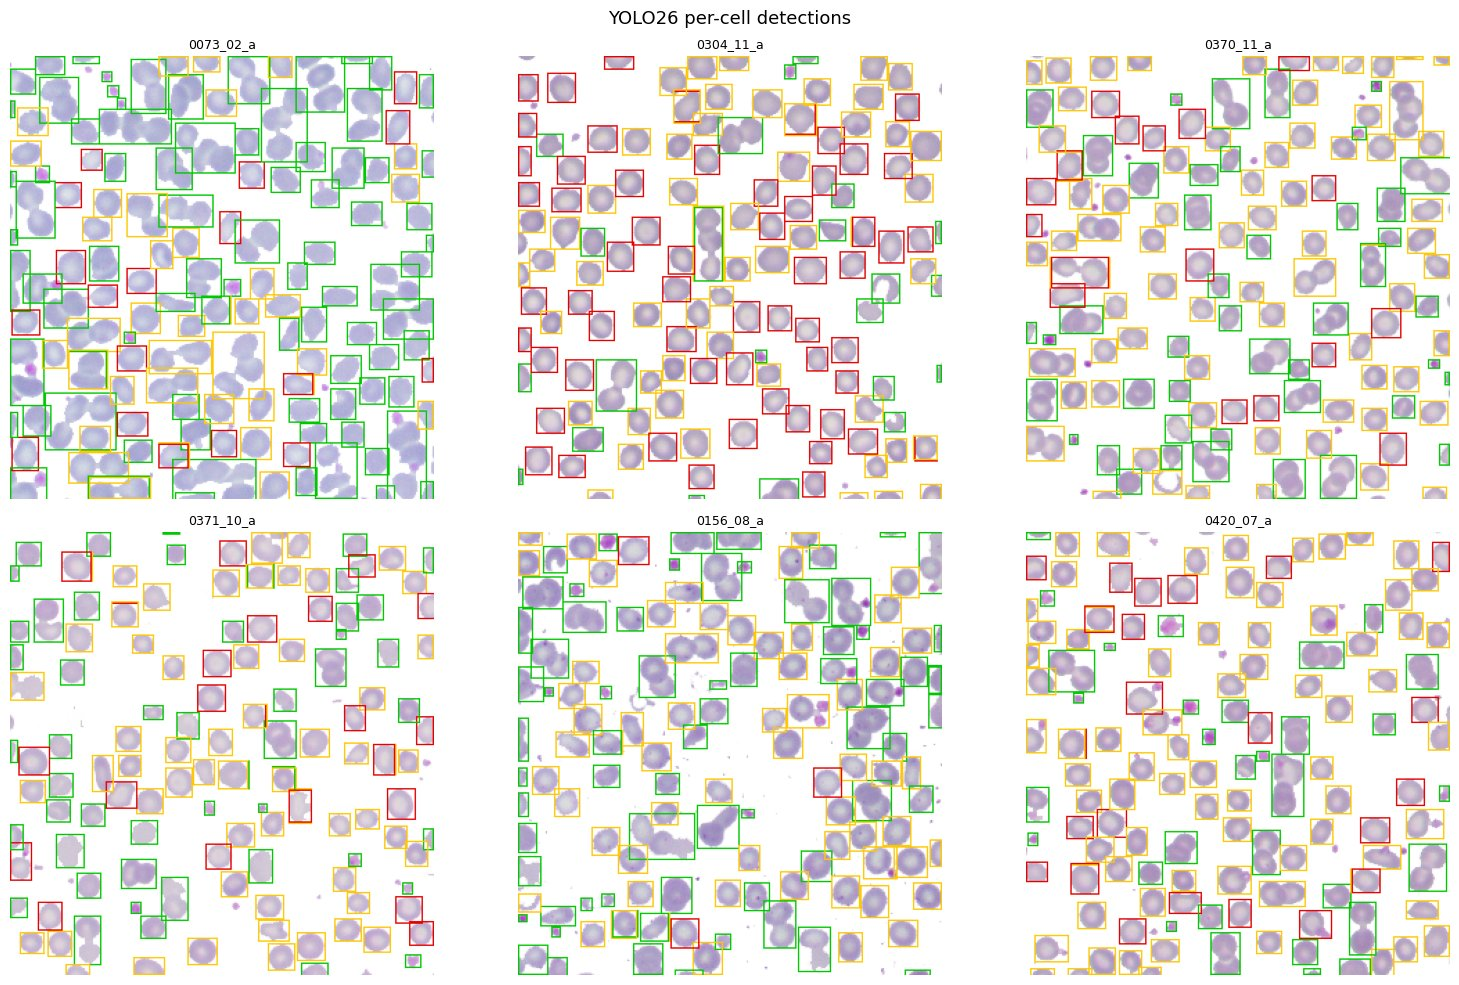

In [10]:
field_grid([None] * len(FIELDS), "YOLO26 per-cell detections", "00_detections.png", boxes=True)

## 8. EigenCAM on the YOLO26 backbone
EigenCAM projects the layer's activations onto their first principal component. The coarse P3 neck map (stride 8 after upsampling, ~3–4 feature pixels per cell) is not used. Maps come from the last stride-4 and stride-8 **backbone** layers.

In [11]:
def capture(rgb, idxs):
    feats, hooks = {}, []
    for i in idxs:
        def h(_m, _inp, o, i=i):
            o = o[0] if isinstance(o, (list, tuple)) else o
            feats[i] = o.detach().float()
        hooks.append(LAYERS[i].register_forward_hook(h))
    lb, geo = letterbox(rgb)
    x = torch.from_numpy(lb).permute(2, 0, 1)[None].float().div(255).to(DEV)
    with torch.no_grad():
        cam_net(x)
    for h in hooks: h.remove()
    return feats, geo

def pick_backbone_layers():
    feats, _ = capture(FIELDS[0]["rgb"], list(range(BACKBONE_END)))
    def last(stride):
        c = [i for i, f in feats.items() if f.dim() == 4 and f.shape[-1] == S // stride and f.shape[1] >= 32]
        return max(c) if c else None
    out = {k: v for k, v in (("stride-4", last(4)), ("stride-8", last(8))) if v is not None}
    for k, i in out.items():
        print(f"{k}: layer {i} ({type(LAYERS[i]).__name__}, {tuple(feats[i].shape[1:])})")
    return out

def eigencam(feat):
    A = feat[0]; C, H, W = A.shape
    X = A.reshape(C, H * W).T
    X = X - X.mean(0, keepdim=True)
    evals, evecs = torch.linalg.eigh(X.T @ X)
    proj = X @ evecs[:, -1]
    if torch.corrcoef(torch.stack([proj, A.reshape(C, -1).norm(dim=0)]))[0, 1] < 0:
        proj = -proj
    return proj.clamp(min=0).reshape(H, W).cpu().numpy(), float(evals[-1] / evals.clamp(min=0).sum())

def eigencam_maps(rgb):
    feats, geo = capture(rgb, list(EC_LAYERS.values()))
    per, var = {}, {}
    for name, i in EC_LAYERS.items():
        m, ev = eigencam(feats[i])
        per[name] = norm01(np.clip(unletterbox(m, geo, rgb.shape), 0, None)); var[name] = ev
    fused = norm01(np.exp(np.mean([np.log(m + 1e-3) for m in per.values()], 0)))   # geometric mean
    return per, fused, var

def pseudo_eigencam(cam, cells):
    # EigenCAM restricted to cell pixels and min-max normalised within each cell
    out = np.zeros_like(cam)
    lab, _ = ndi.label(cells)
    for i, sl in enumerate(ndi.find_objects(lab), 1):
        if sl is None: continue
        m = lab[sl] == i; v = cam[sl][m]
        if v.size >= 10: out[sl][m] = (v - v.min()) / (v.max() - v.min() + 1e-8)
    return out

EC_LAYERS = pick_backbone_layers()
for f in FIELDS:
    f["ec"], f["ec_fused"], f["ec_var"] = eigencam_maps(f["rgb"])
    f["ec_pseudo"] = pseudo_eigencam(f["ec_fused"], f["cells"])

stride-4: layer 2 (C3k2, (128, 160, 160))
stride-8: layer 4 (C3k2, (256, 80, 80))


### 8a. EigenCAM — stride-4 backbone layer

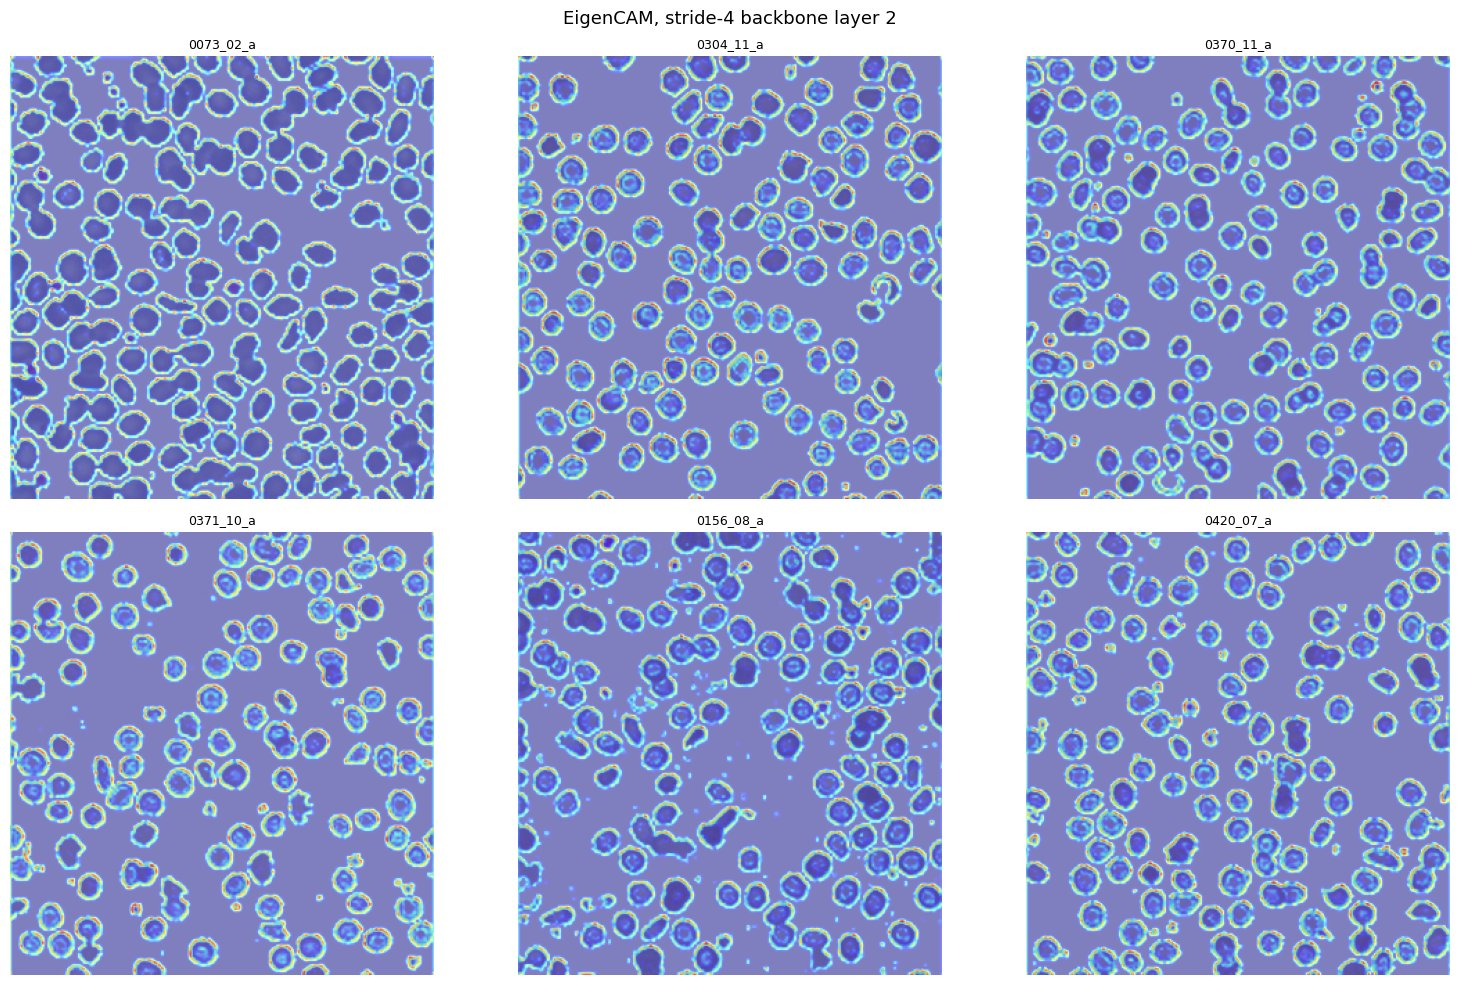

In [12]:
if "stride-4" in EC_LAYERS:
    field_grid([f["ec"]["stride-4"] for f in FIELDS],
               f"EigenCAM, stride-4 backbone layer {EC_LAYERS['stride-4']}", "01_eigencam_stride4.png")

### 8b. EigenCAM — stride-8 backbone layer

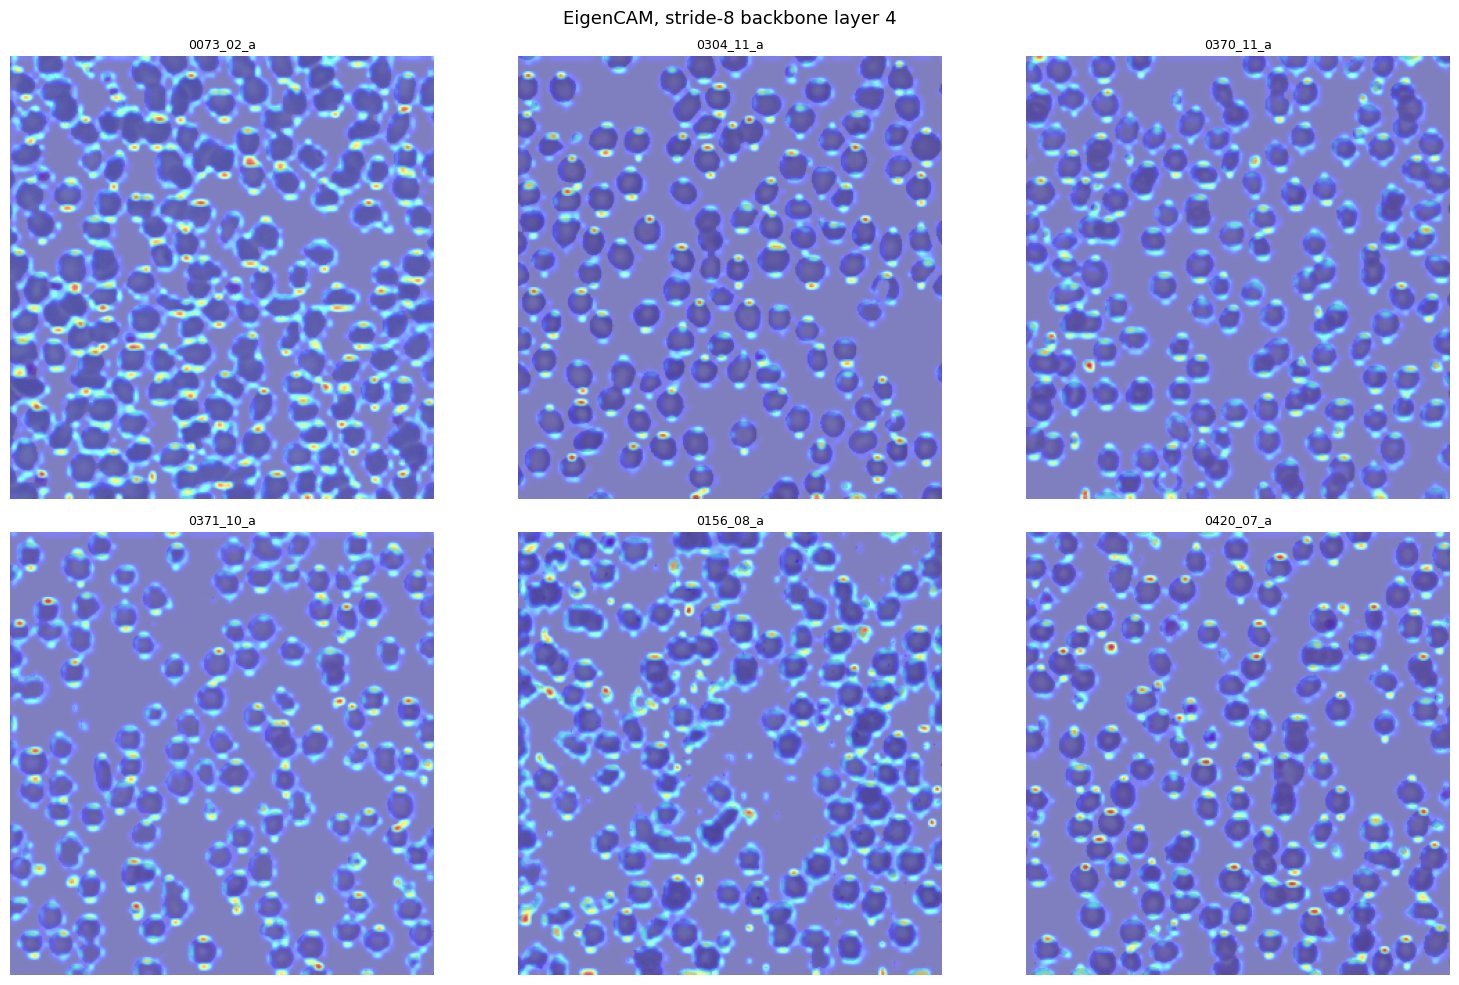

In [13]:
if "stride-8" in EC_LAYERS:
    field_grid([f["ec"]["stride-8"] for f in FIELDS],
               f"EigenCAM, stride-8 backbone layer {EC_LAYERS['stride-8']}", "02_eigencam_stride8.png")

### 8c. Multi-layer EigenCAM (stride-4 × stride-8, geometric mean)

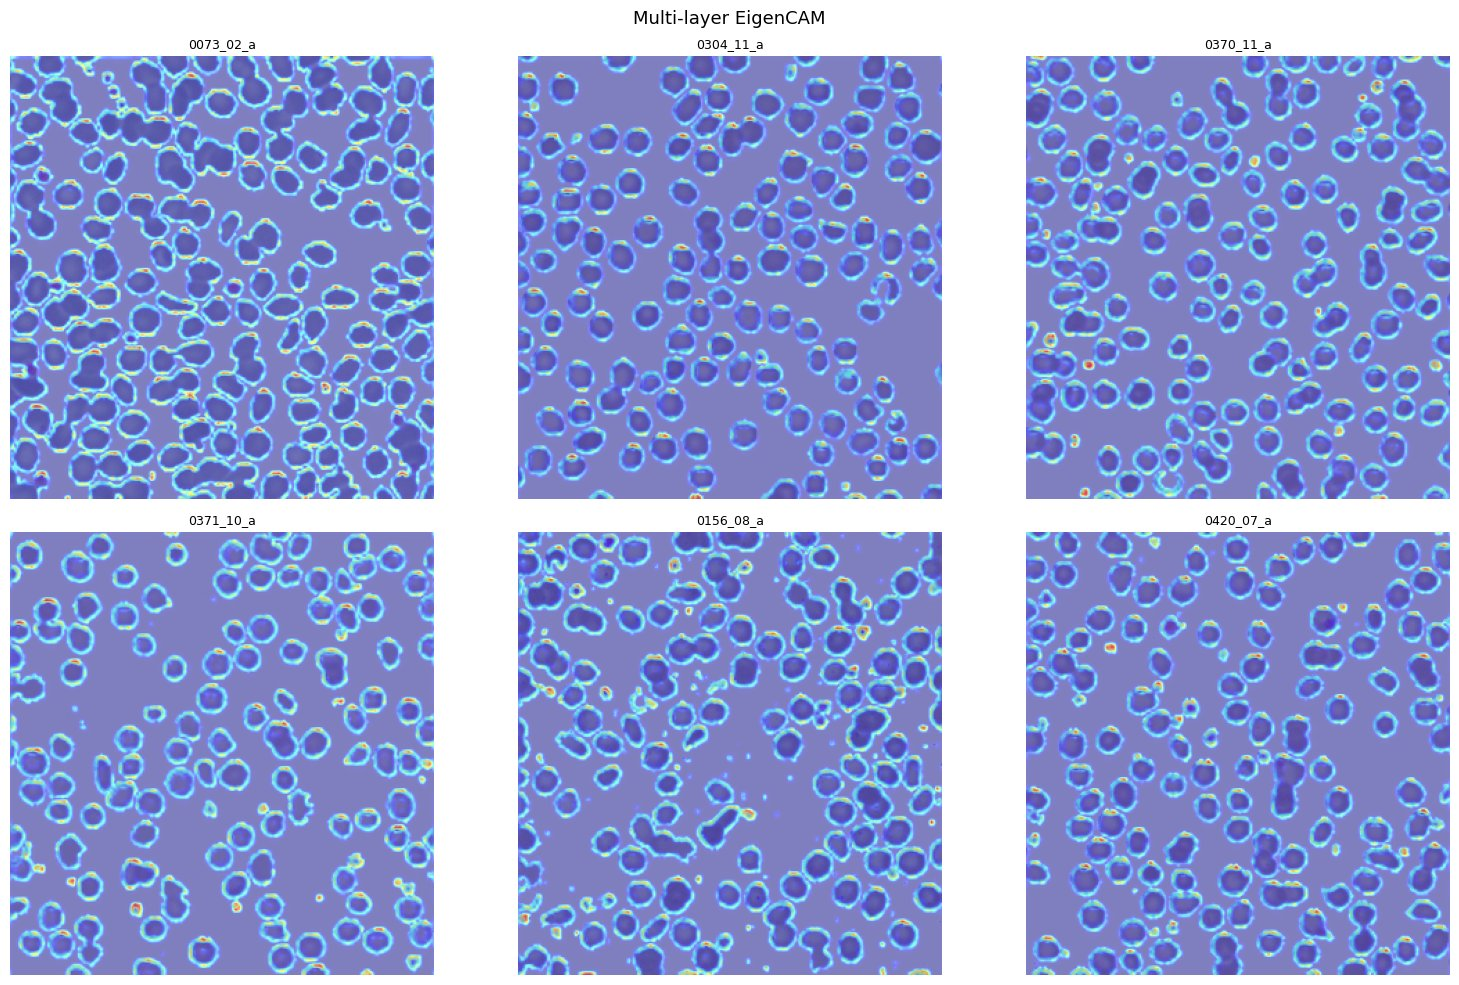

    field  PC1 variance stride-4  PC1 variance stride-8
0073_02_a                  0.098                  0.089
0304_11_a                  0.103                  0.097
0370_11_a                  0.105                  0.087
0371_10_a                  0.106                  0.097
0156_08_a                  0.105                  0.082
0420_07_a                  0.103                  0.097


In [14]:
field_grid([f["ec_fused"] for f in FIELDS], "Multi-layer EigenCAM", "03_eigencam_multilayer.png")
print(pd.DataFrame([dict(field=f["key"], **{f"PC1 variance {k}": v for k, v in f["ec_var"].items()})
                    for f in FIELDS]).round(3).to_string(index=False))

### 8d. Pseudo-EigenCAM (cell-gated)
The multi-layer EigenCAM shown only inside segmented cells and normalised within each cell. In a paper, describe it as *EigenCAM restricted to segmented cells and normalised per cell*.

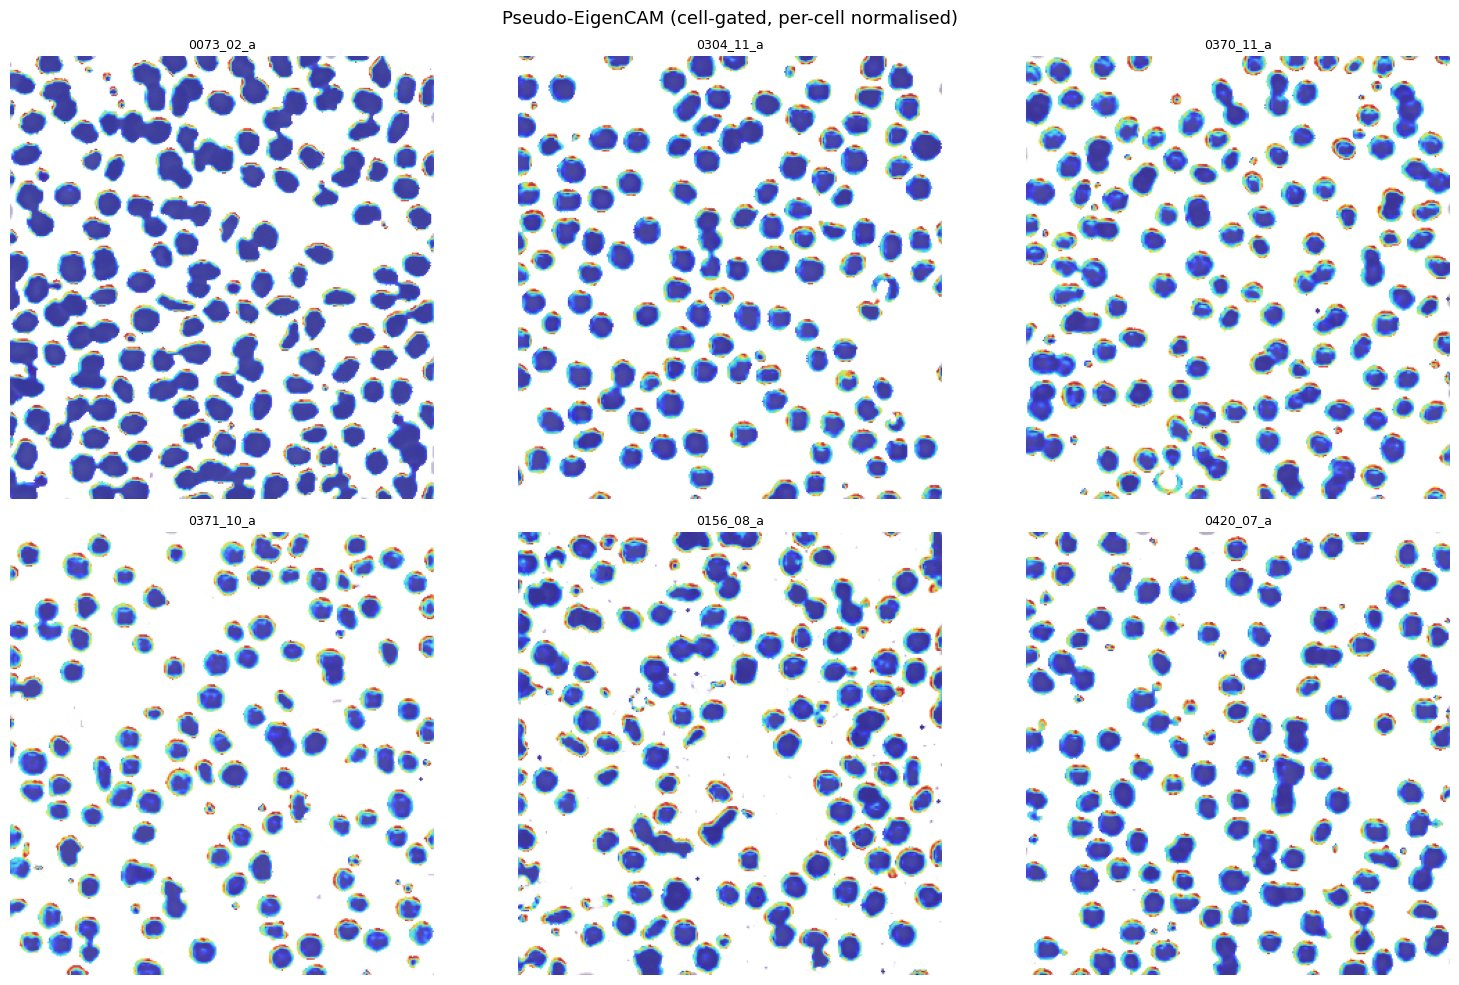

In [15]:
field_grid([f["ec_pseudo"] for f in FIELDS], "Pseudo-EigenCAM (cell-gated, per-cell normalised)",
           "04_pseudo_eigencam.png", alpha=0.65, gate=True)

### 8e. Intensity reference — not an explanation
The jet colour map of image lightness, which is what the ClariScan *pseudo Grad-CAM* shows. It uses no model information and is shown only for comparison.

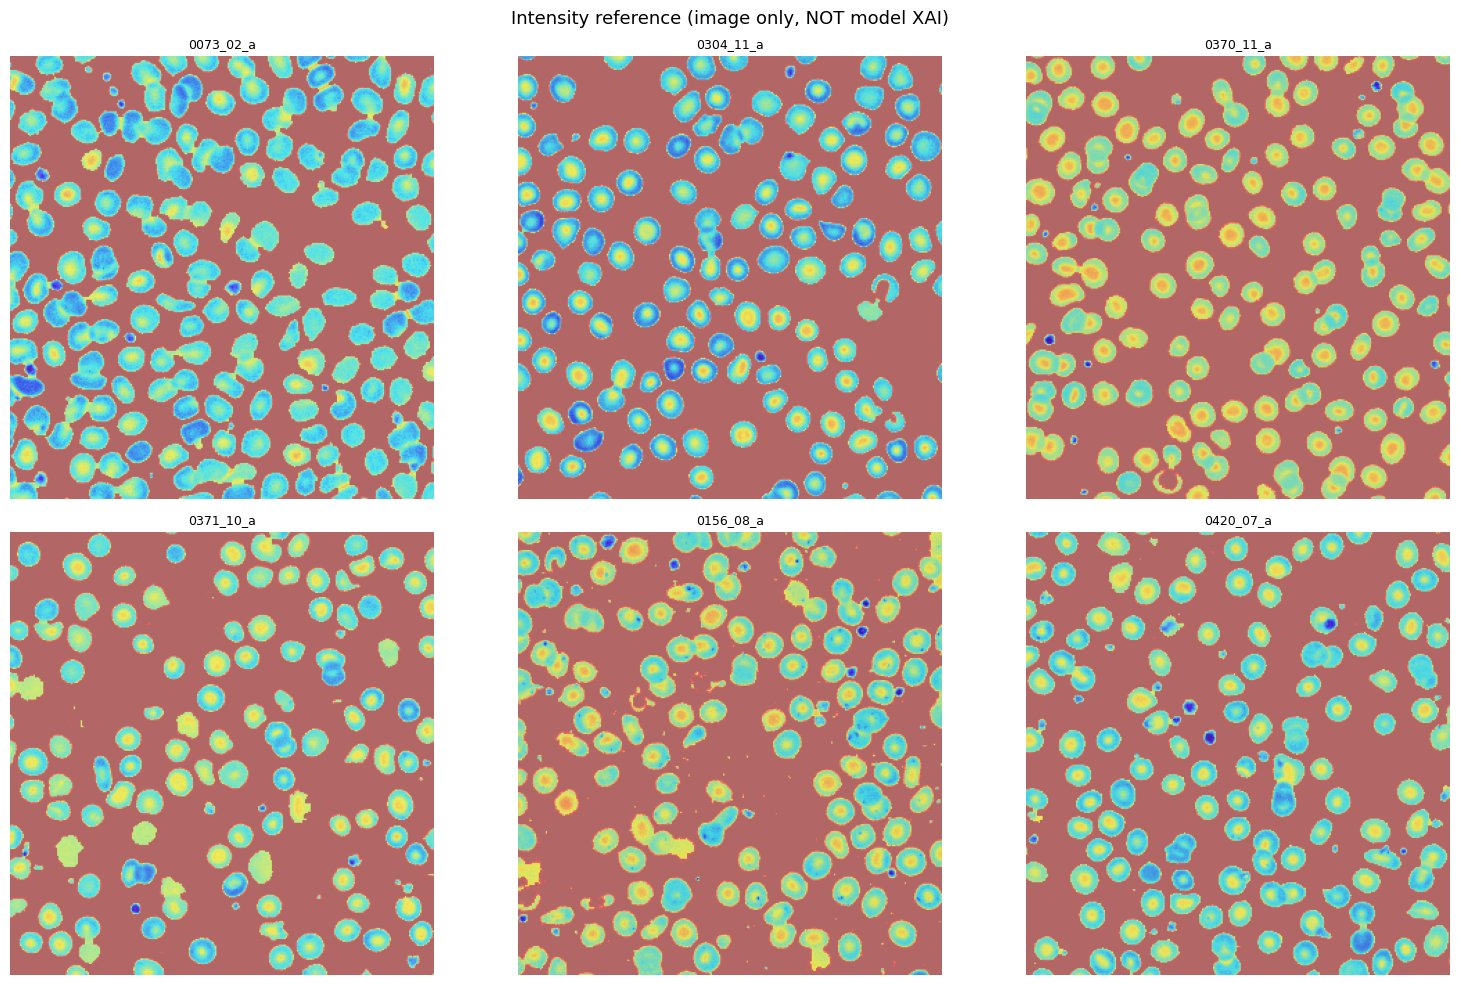

In [16]:
field_grid([cv2.cvtColor(f["rgb"], cv2.COLOR_RGB2GRAY) for f in FIELDS],
           "Intensity reference (image only, NOT model XAI)", "05_intensity_reference.png", alpha=0.6)

## 9. D-RISE — per-detection explanation
Random masks (16 × 16 grid, keep probability 0.5) are applied to the field. Each mask is weighted by how well the masked field still reproduces the target detection (IoU × confidence of the best same-class detection). Masked regions are painted with the slide-background colour.

In [17]:
def select_targets(f, k):
    order = np.argsort(-f["conf"]); keep = order[f["conf"][order] >= CFG["CONF"]]
    chosen = []
    for c in (0, 1, 2):
        chosen += [i for i in keep if f["cls"][i] == c][:int(np.ceil(k / 3))]
    chosen += [i for i in keep if i not in chosen]
    chosen = chosen[:k]
    return f["boxes"][chosen], f["cls"][chosen]

def similarity(pred, tb, tc):
    pb, pc, ps = pred
    if len(pb) == 0: return np.zeros(len(tb))
    return (iou_mat(tb, pb) * ps[None, :] * (tc[:, None] == pc[None, :])).max(1)

def rise_masks(n, H, W, rng):
    g = CFG["DRISE_GRID"]; ch, cw = int(np.ceil(H / g)), int(np.ceil(W / g))
    out = np.empty((n, H, W), np.float32)
    for k in range(n):
        grid = (rng.random((g, g)) < CFG["DRISE_P"]).astype(np.float32)
        up = cv2.resize(grid, ((g + 1) * cw, (g + 1) * ch), interpolation=cv2.INTER_LINEAR)
        dx, dy = rng.integers(0, cw), rng.integers(0, ch)
        out[k] = up[dy:dy + H, dx:dx + W]
    return out

def drise(rgb, tb, tc, seed=0):
    H, W = rgb.shape[:2]; rng = np.random.default_rng(seed)
    bg = bg_color(rgb).astype(np.float32); img = rgb.astype(np.float32)
    sal = np.zeros((len(tb), H, W), np.float32); n = CFG["DRISE_MASKS"]
    for s0 in range(0, n, CFG["PRED_BATCH"]):
        m = rise_masks(min(CFG["PRED_BATCH"], n - s0), H, W, rng)
        imgs = [(img * mk[..., None] + bg * (1 - mk[..., None])).astype(np.uint8) for mk in m]
        w = np.stack([similarity(p, tb, tc) for p in predict(imgs)])      # (batch, targets)
        sal += np.tensordot(w.T, m, axes=(1, 0))
    sal /= n
    return np.stack([np.clip(s - s.mean(), 0, None) for s in sal])       # positive evidence

for j, f in enumerate(FIELDS):
    f["tb"], f["tc"] = select_targets(f, CFG["TARGETS_PER_FIELD"])
    f["drise"] = drise(f["rgb"], f["tb"], f["tc"], seed=j)
    print(f"{f['key']}: D-RISE for {len(f['tb'])} detections")

0073_02_a: D-RISE for 6 detections
0304_11_a: D-RISE for 6 detections
0370_11_a: D-RISE for 6 detections
0371_10_a: D-RISE for 6 detections
0156_08_a: D-RISE for 6 detections
0420_07_a: D-RISE for 6 detections


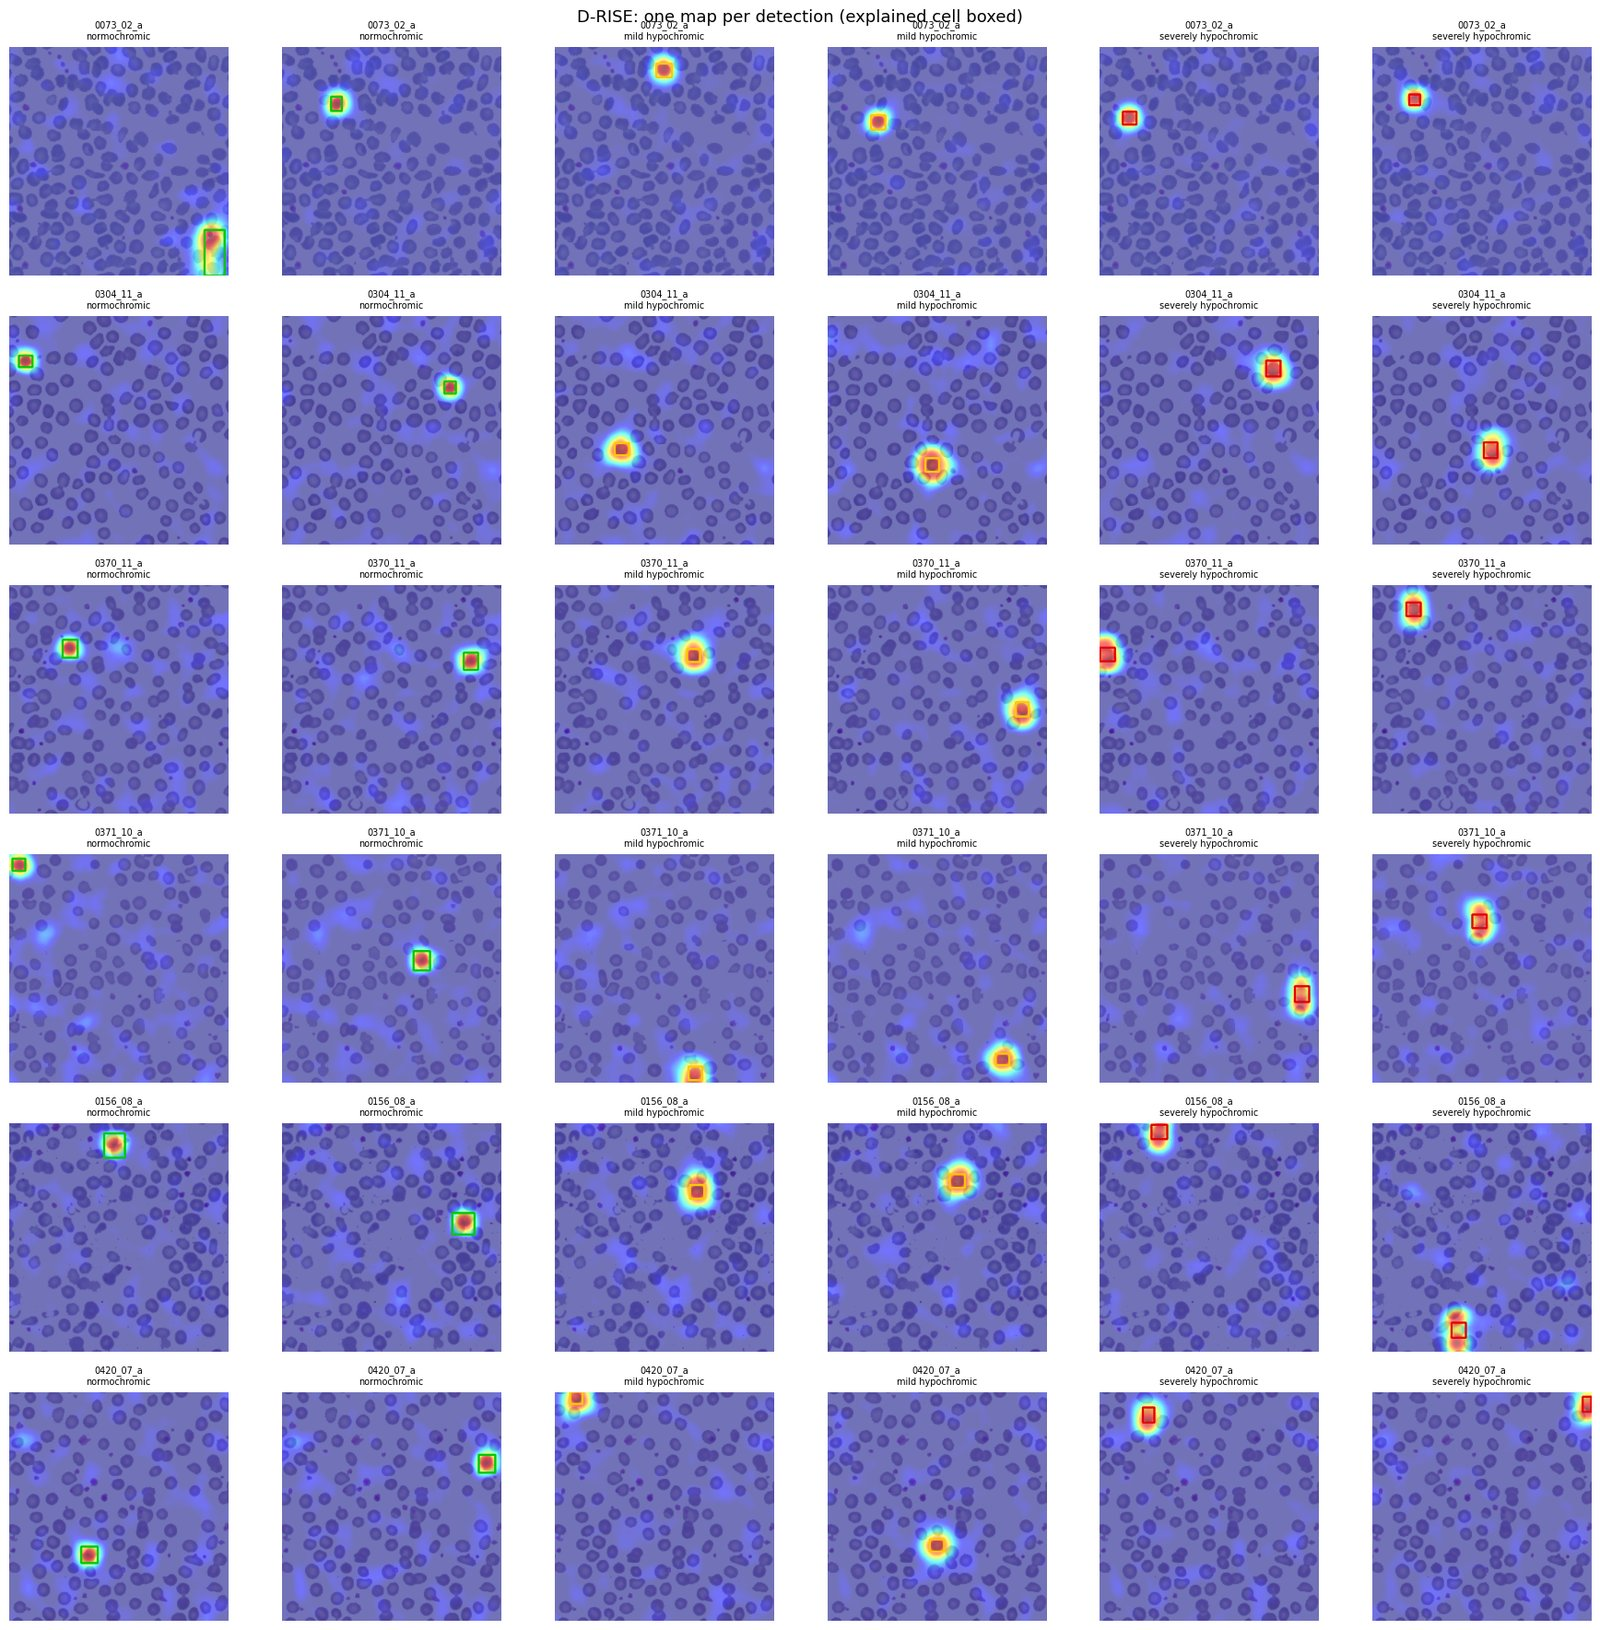

In [18]:
def target_grid(key, title, fname):
    cols = CFG["TARGETS_PER_FIELD"]
    fig, axs = plt.subplots(len(FIELDS), cols, figsize=(3.0 * cols, 3.0 * len(FIELDS)))
    axs = np.atleast_2d(axs)
    for r, f in enumerate(FIELDS):
        for c in range(cols):
            a = axs[r, c]; a.axis("off")
            if c >= len(f["tb"]): continue
            im = draw_boxes(overlay(f["rgb"], f[key][c], 0.55), f["tb"][c:c + 1], f["tc"][c:c + 1], thick=2)
            a.imshow(im); a.set_title(f"{f['key']}\n{CLASS_NAMES[int(f['tc'][c])]}", fontsize=7)
    fig.suptitle(title, fontsize=13); plt.tight_layout()
    save_show(fig, fname)

target_grid("drise", "D-RISE: one map per detection (explained cell boxed)", "06_drise.png")

## 10. GradientSHAP — per-detection explanation
Expected gradients of the target cell's class logit (read at the cell centre on each detection-head level) with respect to the input. Baselines are the slide-background image and a blurred copy of the field; 32 samples per detection, light Gaussian smoothing.

In [19]:
def find_cls_convs():
    convs = [(n, m) for n, m in DETECT.named_modules() if isinstance(m, nn.Conv2d) and m.out_channels == NC]
    o2m = [(n, m) for n, m in convs if "one2one" not in n]   # one-to-one branch uses detached features
    return o2m or convs

CLS_CONVS = find_cls_convs()
print("Class-logit layers used:", [n for n, _ in CLS_CONVS])

def target_score(outs, c, cx, cy):
    vals = []
    for o in outs.values():
        if not torch.is_tensor(o) or o.dim() != 4: continue
        h, w = o.shape[-2:]; st = S / w
        ix = int(np.clip(cx // st, 0, w - 1)); iy = int(np.clip(cy // st, 0, h - 1))
        vals.append(o[:, c, iy, ix])
    return torch.stack(vals, 0).max(0).values

def gradshap(rgb, tb, tc):
    lb, geo = letterbox(rgb); top, left, nh, nw = geo; r = nw / rgb.shape[1]
    x = torch.from_numpy(lb).permute(2, 0, 1)[None].float().div(255).to(DEV)
    b_bg = x.clone()
    b_bg[..., top:top + nh, left:left + nw] = torch.tensor(bg_color(rgb) / 255.0, dtype=torch.float32,
                                                           device=DEV).view(1, 3, 1, 1)
    b_blur = torch.from_numpy(cv2.GaussianBlur(lb, (0, 0), 8)).permute(2, 0, 1)[None].float().div(255).to(DEV)
    outs = {}
    hooks = [m.register_forward_hook(lambda mod, inp, o, key=n: outs.__setitem__(key, o)) for n, m in CLS_CONVS]
    maps = np.zeros((len(tb), *rgb.shape[:2]), np.float32)
    try:
        for t, (box, c) in enumerate(zip(tb, tc)):
            cx = (box[0] + box[2]) / 2 * r + left; cy = (box[1] + box[3]) / 2 * r + top
            acc = torch.zeros(S, S, device=DEV); done = 0
            while done < CFG["GSHAP_SAMPLES"]:
                bsz = min(CFG["GSHAP_BATCH"], CFG["GSHAP_SAMPLES"] - done)
                pick = torch.rand(bsz, 1, 1, 1, device=DEV) < 0.5
                base = torch.where(pick, b_bg.expand(bsz, -1, -1, -1), b_blur.expand(bsz, -1, -1, -1))
                alpha = torch.rand(bsz, 1, 1, 1, device=DEV)
                xin = (base + alpha * (x - base) + CFG["GSHAP_NOISE"] * torch.randn_like(base)).clamp(0, 1)
                xin = xin.detach().requires_grad_(True)
                outs.clear()
                with torch.enable_grad():
                    cam_net(xin)
                    score = target_score(outs, int(c), cx, cy)
                    g, = torch.autograd.grad(score.sum(), xin)
                acc += ((x - base) * g).sum(1).sum(0)
                done += bsz
            m = (acc / done).cpu().numpy()
            if t == 0 and np.abs(m).sum() == 0:
                raise RuntimeError("zero gradients: the class head does not receive gradients")
            maps[t] = unletterbox(cv2.GaussianBlur(m, (0, 0), CFG["GSHAP_SMOOTH"]), geo, rgb.shape)
    finally:
        for h in hooks: h.remove()
    return np.clip(maps, 0, None)    # positive attribution = evidence for the detection

GSHAP_OK = True
for f in FIELDS:
    try:
        f["gshap"] = gradshap(f["rgb"], f["tb"], f["tc"])
        print(f"{f['key']}: GradientSHAP for {len(f['tb'])} detections")
    except Exception as e:
        print("GradientSHAP skipped:", e); GSHAP_OK = False
        break
if DEV == "cuda": torch.cuda.empty_cache()

Class-logit layers used: ['cv3.0.2', 'cv3.1.2', 'cv3.2.2']
0073_02_a: GradientSHAP for 6 detections
0304_11_a: GradientSHAP for 6 detections
0370_11_a: GradientSHAP for 6 detections
0371_10_a: GradientSHAP for 6 detections
0156_08_a: GradientSHAP for 6 detections
0420_07_a: GradientSHAP for 6 detections


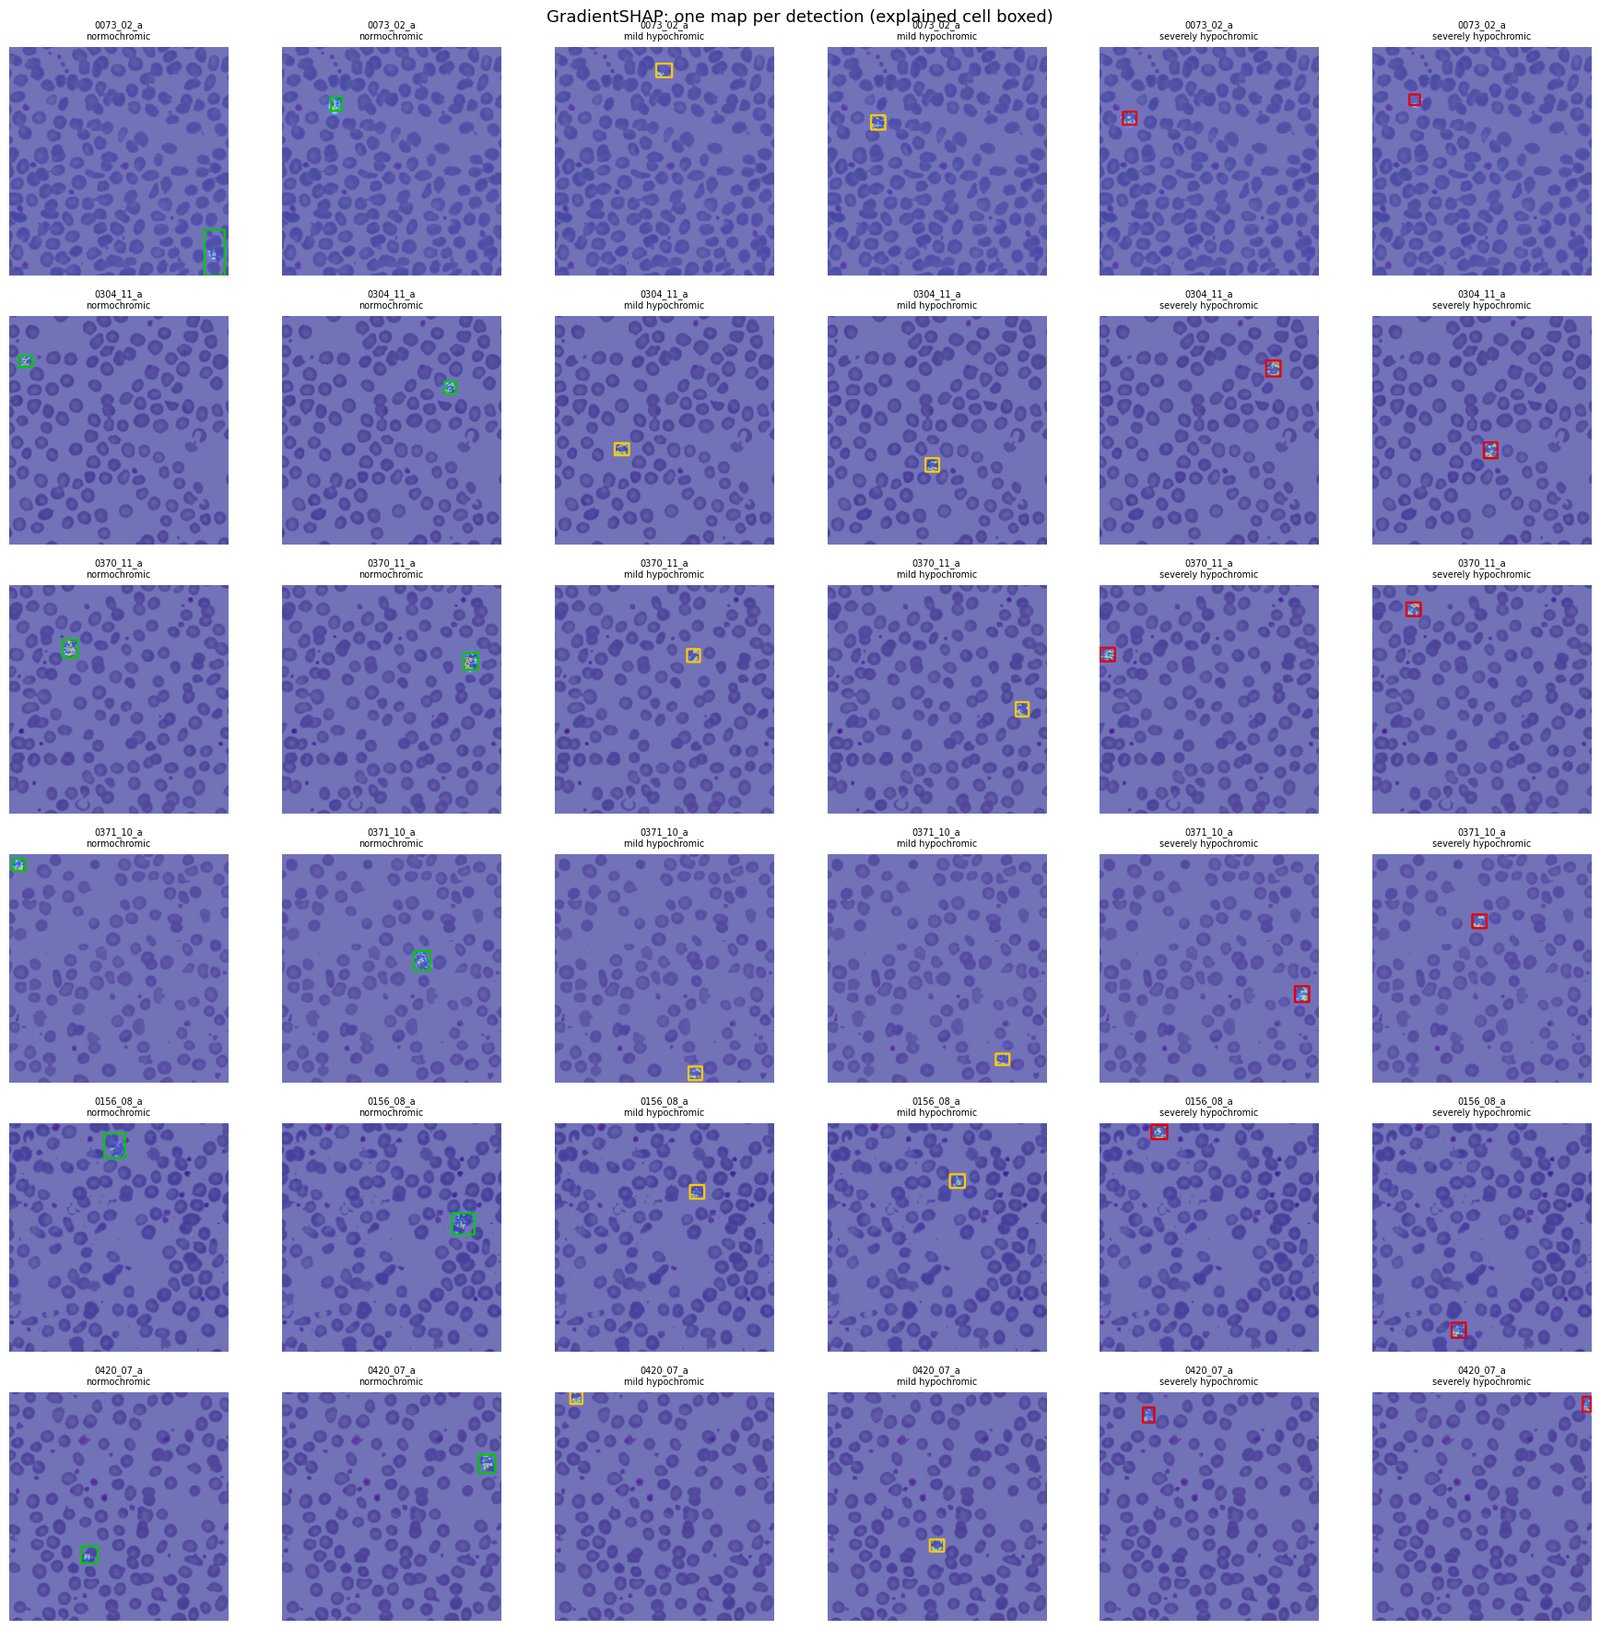

In [20]:
if GSHAP_OK:
    target_grid("gshap", "GradientSHAP: one map per detection (explained cell boxed)", "07_gradshap.png")

## 11. Which explanation is best? Quantitative comparison
All methods are scored on the **same detections**:
- **Deletion AUC** (lower is better): pixels are painted with the background colour in order of saliency (0–90%), and the target detection's score (IoU × confidence) is tracked.
- **Pointing game** (higher is better): the saliency peak falls inside the target box.
- **Energy-in-box** (higher is better; 1 = chance): share of positive saliency inside the box ÷ box share of the field.

EigenCAM is class-agnostic, so the same field map is used for every detection. A smooth random map is the reference.

In [21]:
def deletion_auc(rgb, sal, box, c):
    H, W = sal.shape; bg = bg_color(rgb)
    order = np.argsort(-sal.ravel(), kind="stable"); imgs = []
    for k in range(CFG["DEL_STEPS"]):
        im = rgb.copy().reshape(-1, 3)
        im[order[:int(k / CFG["DEL_STEPS"] * H * W)]] = bg
        imgs.append(im.reshape(H, W, 3))
    s = np.array([similarity(p, box[None], np.array([c]))[0] for p in predict(imgs)])
    return float(np.mean(s / max(s[0], 1e-6)))

def pointing(sal, box):
    y, x = np.unravel_index(np.argmax(sal), sal.shape)
    return float(box[0] <= x <= box[2] and box[1] <= y <= box[3])

def energy_in_box(sal, box):
    pos = np.clip(sal, 0, None); m = np.zeros(sal.shape, bool)
    x0, y0, x1, y1 = box.astype(int); m[max(y0, 0):y1, max(x0, 0):x1] = True
    return float((pos[m].sum() / (pos.sum() + 1e-8)) / max(m.mean(), 1e-8))

rng = np.random.default_rng(CFG["SEED"])
rows = []
for f in FIELDS:
    H, W = f["rgb"].shape[:2]
    for t, (box, c) in enumerate(zip(f["tb"], f["tc"])):
        methods = {"EigenCAM stride-4": f["ec"].get("stride-4"),
                   "EigenCAM stride-8": f["ec"].get("stride-8"),
                   "EigenCAM multi-layer": f["ec_fused"],
                   "Pseudo-EigenCAM": f["ec_pseudo"],
                   "D-RISE": f["drise"][t],
                   "Random (smooth)": cv2.resize(rng.random((14, 14)).astype(np.float32), (W, H),
                                                 interpolation=cv2.INTER_CUBIC)}
        if GSHAP_OK: methods["GradientSHAP"] = f["gshap"][t]
        for name, sal in methods.items():
            if sal is None: continue
            rows.append(dict(field=f["key"], target=t, cls=CLASS_NAMES[int(c)], method=name,
                             deletion_auc=deletion_auc(f["rgb"], sal, box, int(c)),
                             pointing=pointing(sal, box), energy_in_box=energy_in_box(sal, box)))
    print("scored", f["key"])
XAI = pd.DataFrame(rows); XAI.to_csv(OUT / "xai_method_scores.csv", index=False)

scored 0073_02_a
scored 0304_11_a
scored 0370_11_a
scored 0371_10_a
scored 0156_08_a
scored 0420_07_a


### Best explanation for the YOLO26 detections: **GradientSHAP**

,deletion_auc,pointing,energy_in_box,n,rank_score
method,,,,,
GradientSHAP,0.120,0.972,154.626,36,1.333
D-RISE,0.101,0.889,31.140,36,1.667
EigenCAM stride-4,0.241,0.056,1.806,36,3.667
Pseudo-EigenCAM,0.223,0.000,1.963,36,4.000
EigenCAM multi-layer,0.264,0.000,1.625,36,5.333
EigenCAM stride-8,0.342,0.000,1.247,36,6.000
Random (smooth),0.452,0.028,1.095,36,6.000


**By class (deletion AUC, lower is better)**

cls,mild hypochromic,normochromic,severely hypochromic
method,,,
D-RISE,0.100,0.104,0.100
EigenCAM multi-layer,0.164,0.303,0.327
EigenCAM stride-4,0.152,0.299,0.272
EigenCAM stride-8,0.266,0.336,0.424
GradientSHAP,0.142,0.117,0.101
Pseudo-EigenCAM,0.156,0.300,0.214
Random (smooth),0.471,0.490,0.394


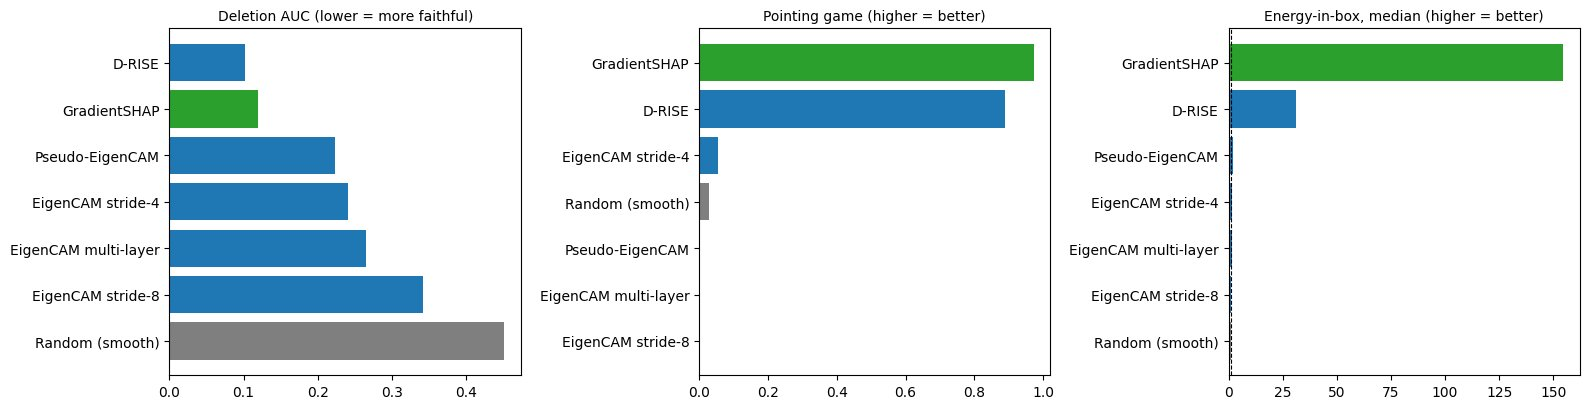

In [22]:
summ = XAI.groupby("method").agg(deletion_auc=("deletion_auc", "mean"), pointing=("pointing", "mean"),
                                 energy_in_box=("energy_in_box", "median"), n=("target", "size"))
summ["rank_score"] = (summ["deletion_auc"].rank() + summ["pointing"].rank(ascending=False)
                      + summ["energy_in_box"].rank(ascending=False)) / 3
summ = summ.sort_values("rank_score")
real = summ.drop(index="Random (smooth)", errors="ignore")
BEST = real.index[0]
summ.to_csv(OUT / "xai_method_summary.csv")
display(Markdown(f"### Best explanation for the YOLO26 detections: **{BEST}**"))
display(summ.round(3))
display(Markdown("**By class (deletion AUC, lower is better)**"))
display(XAI.pivot_table(index="method", columns="cls", values="deletion_auc", aggfunc="mean").round(3))

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (col, lab) in zip(axs, [("deletion_auc", "Deletion AUC (lower = more faithful)"),
                               ("pointing", "Pointing game (higher = better)"),
                               ("energy_in_box", "Energy-in-box, median (higher = better)")]):
    v = summ[col].sort_values(ascending=(col == "deletion_auc"))
    a.barh(v.index[::-1], v.values[::-1],
           color=["tab:green" if i == BEST else "tab:gray" if i == "Random (smooth)" else "tab:blue" for i in v.index[::-1]])
    a.set_title(lab, fontsize=10)
    if col == "energy_in_box": a.axvline(1, ls="--", c="k", lw=0.8)
plt.tight_layout(); save_show(fig, "08_xai_comparison.png")

## 12. Side-by-side cell views
Zoomed crops of explained cells (box shows the explained detection). Columns are the methods.

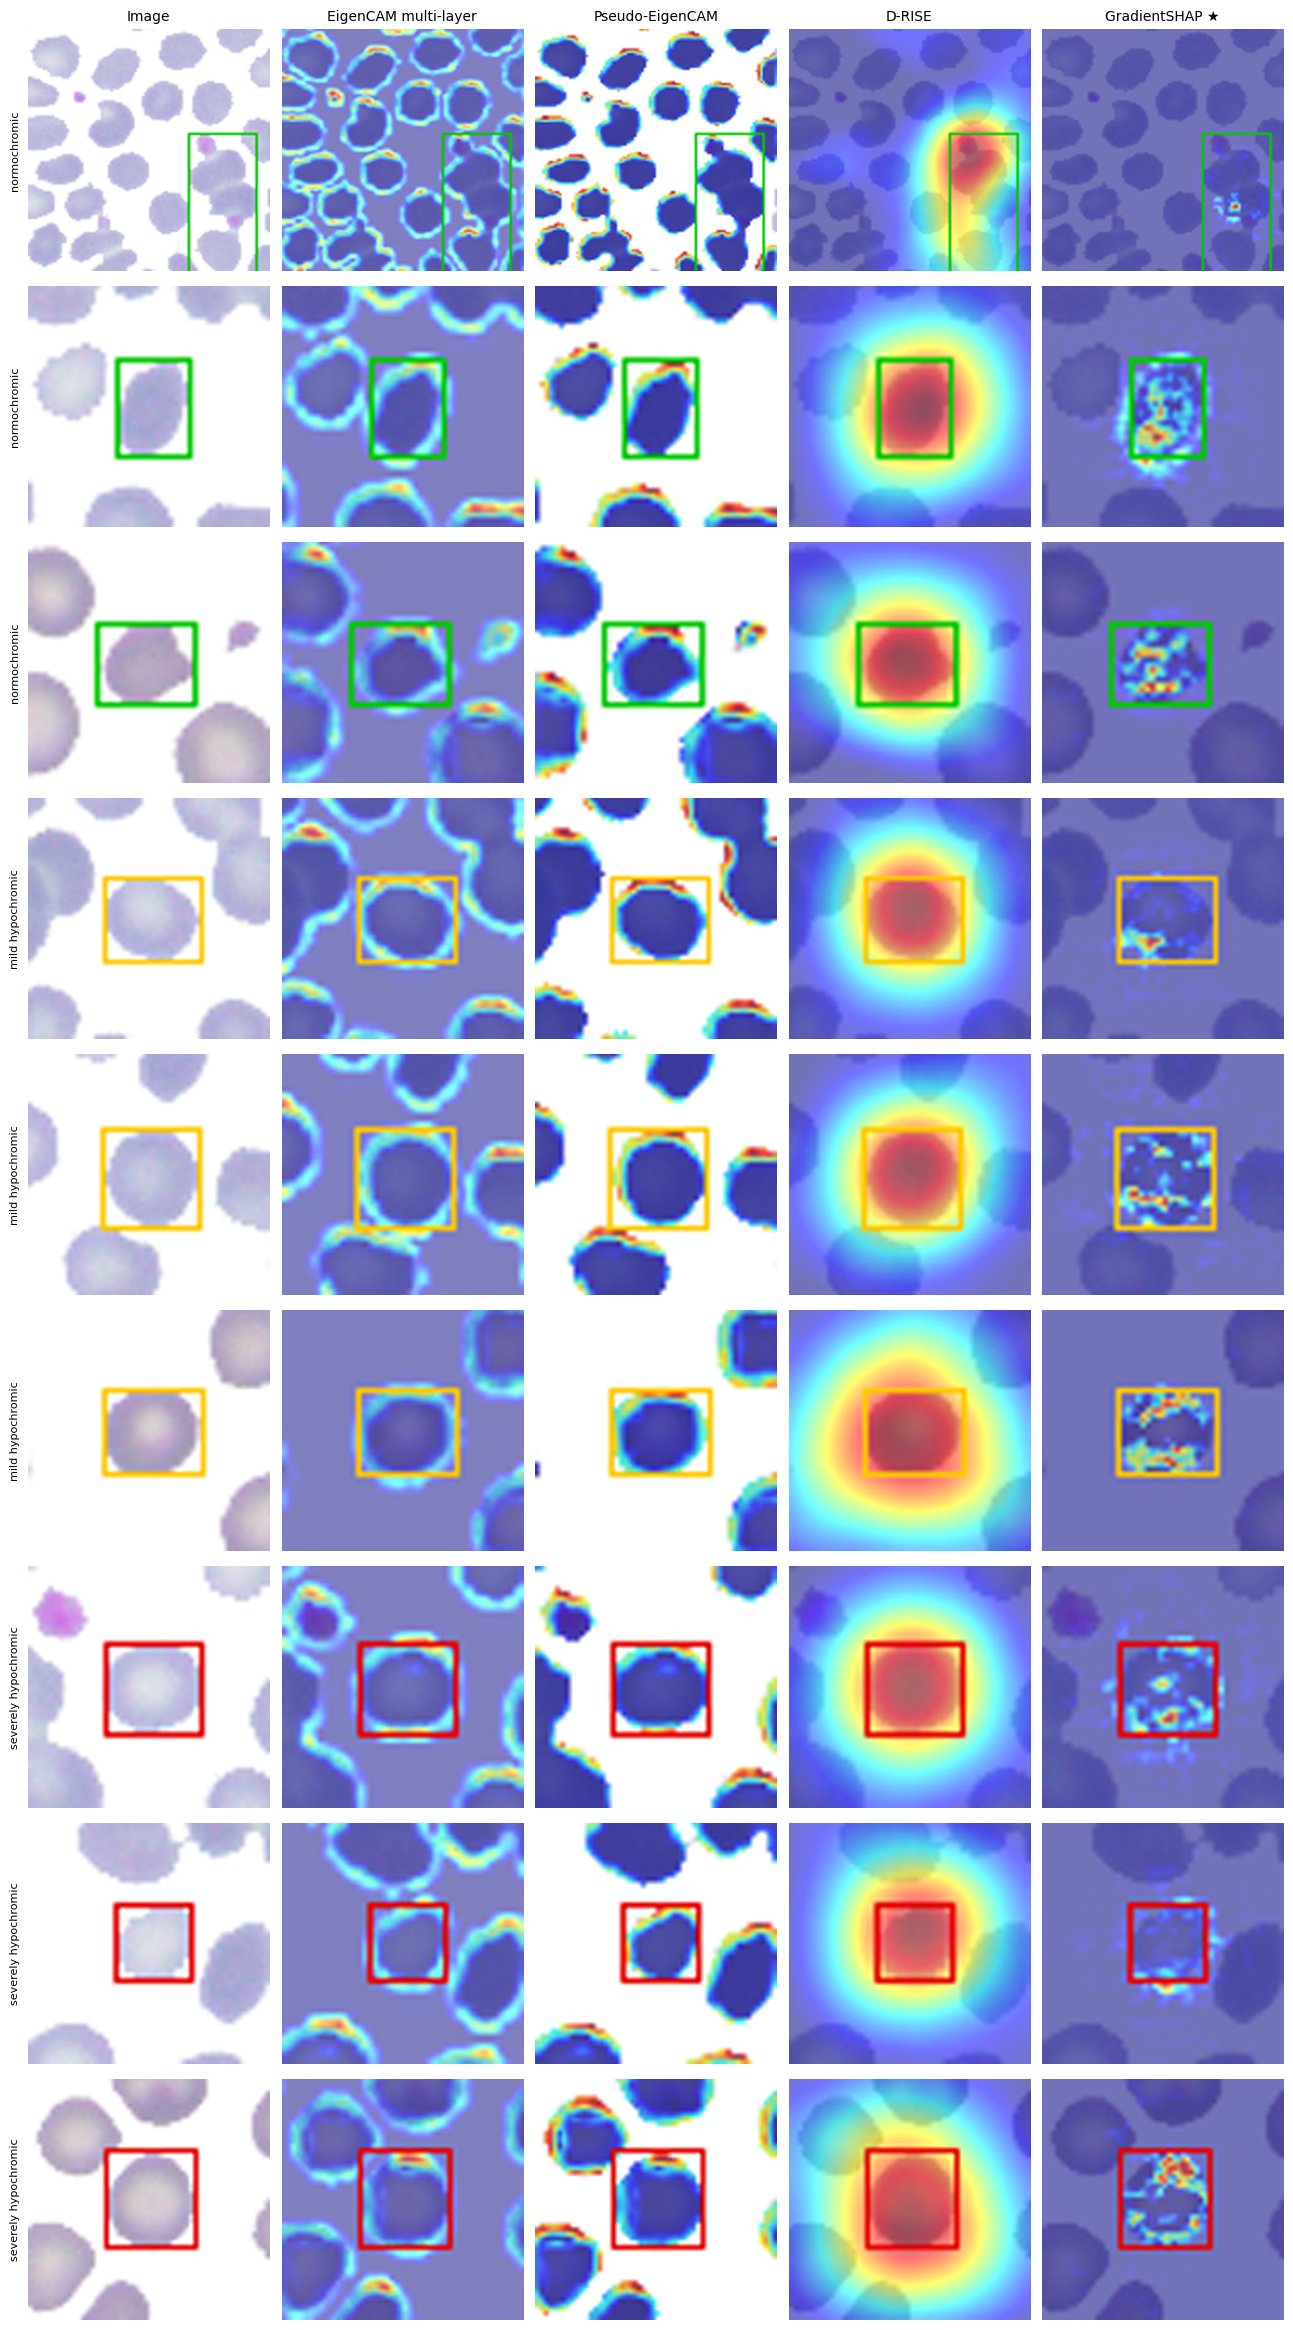

In [23]:
def crop(img, box, scale=2.5, out=224):
    H, W = img.shape[:2]; cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    half = max(24, scale * max(box[2] - box[0], box[3] - box[1]) / 2)
    x0, x1 = int(max(0, cx - half)), int(min(W, cx + half)); y0, y1 = int(max(0, cy - half)), int(min(H, cy + half))
    return cv2.resize(img[y0:y1, x0:x1], (out, out), interpolation=cv2.INTER_CUBIC)

cols = ["Image", "EigenCAM multi-layer", "Pseudo-EigenCAM", "D-RISE"] + (["GradientSHAP"] if GSHAP_OK else [])
picked = []
for c in (0, 1, 2):
    picked += [(f, t) for f in FIELDS for t in range(len(f["tb"])) if f["tc"][t] == c][:3]
fig, axs = plt.subplots(len(picked), len(cols), figsize=(2.6 * len(cols), 2.6 * len(picked)))
axs = np.atleast_2d(axs)
for r, (f, t) in enumerate(picked):
    box, c = f["tb"][t], int(f["tc"][t])
    maps = {"EigenCAM multi-layer": overlay(f["rgb"], f["ec_fused"]),
            "Pseudo-EigenCAM": overlay(f["rgb"], f["ec_pseudo"], 0.65, f["cells"].astype(np.float32)),
            "D-RISE": overlay(f["rgb"], f["drise"][t], 0.55), "Image": f["rgb"]}
    if GSHAP_OK: maps["GradientSHAP"] = overlay(f["rgb"], f["gshap"][t], 0.55)
    for k, col in enumerate(cols):
        a = axs[r, k]; a.imshow(crop(draw_boxes(maps[col], box[None], [c], 1), box)); a.axis("off")
        if r == 0: a.set_title(col + (" ★" if col == BEST else ""), fontsize=10)
    axs[r, 0].text(-8, 112, CLASS_NAMES[c], rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout(); save_show(fig, "09_cell_views.png")

## 13. Best method on whole fields

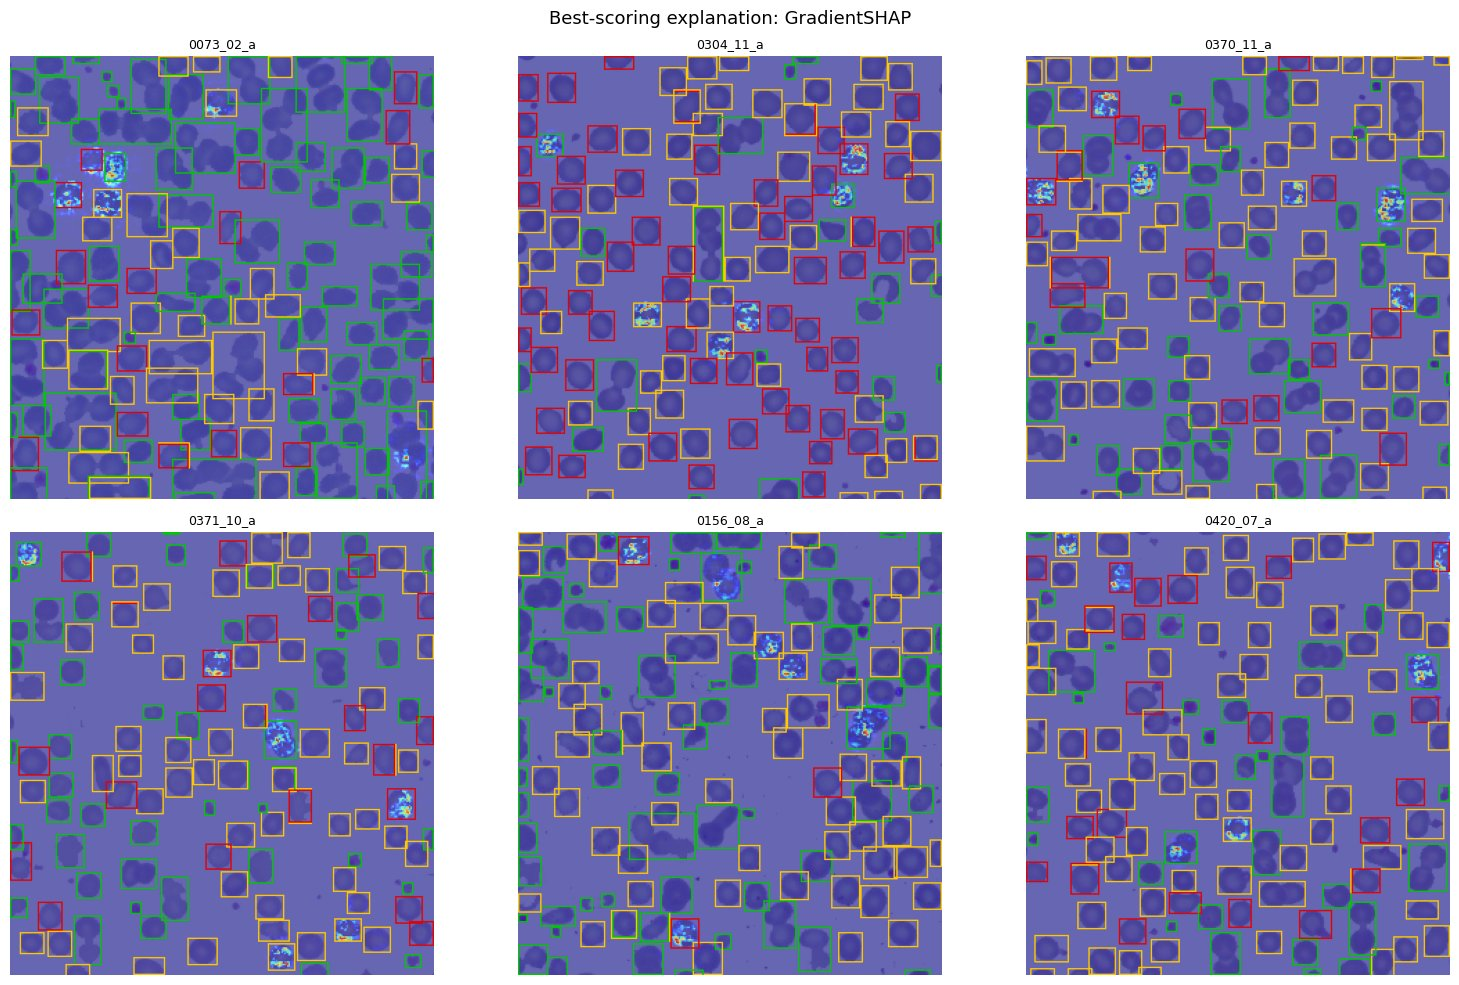

In [24]:
def best_maps():
    key = {"D-RISE": "drise", "GradientSHAP": "gshap"}.get(BEST)
    if key:   # per-detection method: show the strongest map among the explained cells
        return [np.max(np.stack([norm01(m) for m in f[key]]), 0) for f in FIELDS], False
    if BEST == "Pseudo-EigenCAM": return [f["ec_pseudo"] for f in FIELDS], True
    if BEST == "EigenCAM multi-layer": return [f["ec_fused"] for f in FIELDS], False
    return [f["ec"][BEST.split()[-1]] for f in FIELDS], False

maps, gate = best_maps()
field_grid(maps, f"Best-scoring explanation: {BEST}", "10_best_method_fields.png",
           alpha=0.6, gate=gate, boxes=BEST in ("D-RISE", "GradientSHAP"))

## 14. Does EigenCAM improve detection?
- **V0** baseline YOLO26
- **V1** EigenCAM rescoring: score = conf^(1−λ) · cam^λ, where cam is the mean multi-layer EigenCAM in the central ellipse of the box
- **V2** EigenCAM-guided contrast enhancement (CLAHE on CIELAB lightness, weighted by EigenCAM), then detection

λ, β and the confidence threshold are chosen on a calibration half; results are reported on the other half, with a paired bootstrap 95% CI for the change in mAP@0.5.

In [25]:
def match_image(pred, gb, gc):
    pb, pc, ps = pred; out, ngt = [], {}
    for c in np.unique(np.concatenate([pc, gc])).astype(int):
        P = np.where(pc == c)[0]; G = np.where(gc == c)[0]; ngt[c] = len(G)
        P = P[np.argsort(-ps[P])]; used = np.zeros(len(G), bool); I = iou_mat(pb[P], gb[G])
        for k, j in enumerate(P):
            tp = 0
            if len(G):
                cand_ = np.where((I[k] >= 0.5) & ~used)[0]
                if len(cand_): used[cand_[np.argmax(I[k][cand_])]] = True; tp = 1
            out.append((c, ps[j], tp))
    return np.array(out, float).reshape(-1, 3), ngt

def evaluate(per_image):
    M = np.concatenate([m for m, _ in per_image]); ngt = {}
    for _, g in per_image:
        for c, n in g.items(): ngt[c] = ngt.get(c, 0) + n
    aps, grid = [], np.linspace(0, 1, 101)
    for c, n in ngt.items():
        if n == 0: continue
        r = M[M[:, 0] == c]; r = r[np.argsort(-r[:, 1], kind="stable")]
        if len(r) == 0: aps.append(0.0); continue
        tp = np.cumsum(r[:, 2]); fp = np.cumsum(1 - r[:, 2])
        rec, prec = tp / n, tp / np.maximum(tp + fp, 1e-9)
        env = np.maximum.accumulate(prec[::-1])[::-1]; k = np.searchsorted(rec, grid, side="left")
        aps.append(float(np.mean(np.where(k < len(env), env[np.minimum(k, len(env) - 1)], 0.0))))
    a = M[np.argsort(-M[:, 1], kind="stable")]; tp = np.cumsum(a[:, 2])
    P = tp / np.arange(1, len(a) + 1); R = tp / max(sum(ngt.values()), 1); F = 2 * P * R / np.maximum(P + R, 1e-9)
    k = int(np.argmax(F)) if len(F) else 0
    return dict(mAP50=float(np.mean(aps)) if aps else 0.0, thr=float(a[k, 1]) if len(a) else 1.0)

def at_threshold(per_image, thr):
    M = np.concatenate([m for m, _ in per_image]); M = M[M[:, 1] >= thr]
    tp = M[:, 2].sum(); P = tp / max(len(M), 1); R = tp / max(sum(n for _, g in per_image for n in g.values()), 1)
    return dict(P=float(P), R=float(R), F1=float(2 * P * R / max(P + R, 1e-9)))

def cam_box_scores(cam, boxes):
    H, W = cam.shape; s = np.zeros(len(boxes))
    for j, (x0, y0, x1, y1) in enumerate(boxes):
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2; ax_, ay_ = max(1, 0.3 * (x1 - x0)), max(1, 0.3 * (y1 - y0))
        xa, xb = int(max(0, cx - ax_)), int(min(W, cx + ax_ + 1)); ya, yb = int(max(0, cy - ay_)), int(min(H, cy + ay_ + 1))
        if xb <= xa or yb <= ya: continue
        yy, xx = np.mgrid[ya:yb, xa:xb]; e = ((xx - cx) / ax_) ** 2 + ((yy - cy) / ay_) ** 2 <= 1
        s[j] = cam[ya:yb, xa:xb][e].mean() if e.any() else 0
    return s

def cam_enhance(rgb, cam, beta):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB); L = lab[..., 0]
    Lc = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(L); w = np.clip(beta * cam, 0, 1)
    lab[..., 0] = np.clip(L * (1 - w) + Lc * w, 0, 255).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

In [26]:
store = []
for n, e in enumerate(EVAL):
    _, cam, _ = eigencam_maps(e["rgb"])
    pb, pc, ps = predict([e["rgb"]])[0]
    rec = {"V0": match_image((pb, pc, ps), e["gb"], e["gc"])}
    cs = np.clip(cam_box_scores(cam, pb), 1e-3, 1)
    for l in CFG["LAMBDAS"]:
        rec[f"V1 λ={l}"] = match_image((pb, pc, ps ** (1 - l) * cs ** l), e["gb"], e["gc"])
    enh = predict([cam_enhance(e["rgb"], cam, b) for b in CFG["BETAS"]])
    for b, p in zip(CFG["BETAS"], enh):
        rec[f"V2 β={b}"] = match_image(p, e["gb"], e["gc"])
    store.append(rec)
    if (n + 1) % 50 == 0: print(f"  {n + 1}/{len(EVAL)} fields")

idx = np.random.default_rng(CFG["SEED"]).permutation(len(store)); half = len(store) // 2
CAL, TEST = idx[:half], idx[half:]
ev = lambda v, ids: evaluate([store[i][v] for i in ids])
cal = {v: ev(v, CAL) for v in store[0]}
best1 = max([v for v in cal if v.startswith("V1")], key=lambda v: cal[v]["mAP50"])
best2 = max([v for v in cal if v.startswith("V2")], key=lambda v: cal[v]["mAP50"])
print("Chosen on the calibration half:", best1, "|", best2)

  50/300 fields
  100/300 fields
  150/300 fields
  200/300 fields
  250/300 fields
  300/300 fields
Chosen on the calibration half: V1 λ=0.1 | V2 β=0.25


**Held-out test half: 150 fields**

,method,mAP50,P,R,F1,dmAP50,ci_low,ci_high,verdict
0,V0 baseline YOLO26,0.8035,0.8627,0.8631,0.8629,NaN,NaN,NaN,NaN
1,V1 EigenCAM rescoring (V1 λ=0.1),0.7799,0.8628,0.8522,0.8575,-0.0226,-0.0281,-0.0180,worse
2,V2 EigenCAM-guided enhancement (V2 β=0.25),0.7999,0.8516,0.8622,0.8568,-0.0029,-0.0068,0.0013,no significant change


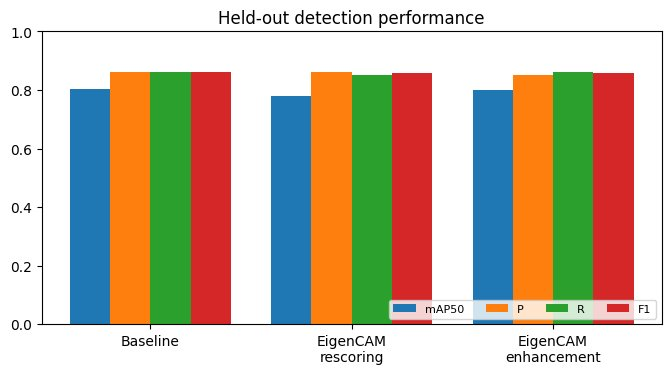

In [27]:
rows, rng = [], np.random.default_rng(CFG["SEED"])
for label, v in [("V0 baseline YOLO26", "V0"), (f"V1 EigenCAM rescoring ({best1})", best1),
                 (f"V2 EigenCAM-guided enhancement ({best2})", best2)]:
    r = dict(method=label, mAP50=ev(v, TEST)["mAP50"], **at_threshold([store[i][v] for i in TEST], cal[v]["thr"]))
    if v != "V0":
        d = []
        for _ in range(CFG["N_BOOT"]):
            sb = rng.choice(TEST, len(TEST), replace=True)
            d.append(ev(v, sb)["mAP50"] - ev("V0", sb)["mAP50"])
        lo, hi = np.percentile(d, [2.5, 97.5])
        r.update(dmAP50=float(np.mean(d)), ci_low=lo, ci_high=hi,
                 verdict="improves" if lo > 0 else "worse" if hi < 0 else "no significant change")
    rows.append(r)
DET = pd.DataFrame(rows); DET.to_csv(OUT / "detection_improvement_test.csv", index=False)
display(Markdown(f"**Held-out test half: {len(TEST)} fields**")); display(DET.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(len(DET)); w = 0.2
for k, m in enumerate(["mAP50", "P", "R", "F1"]):
    ax.bar(x + (k - 1.5) * w, DET[m], w, label=m)
ax.set_xticks(x); ax.set_xticklabels(["Baseline", "EigenCAM\nrescoring", "EigenCAM\nenhancement"])
ax.set_ylim(0, 1); ax.legend(ncol=4, fontsize=8, loc="lower right"); ax.set_title("Held-out detection performance")
save_show(fig, "11_detection_improvement.png")

## 15. Save everything

In [28]:
shutil.make_archive(str(WORK / "xai_outputs"), "zip", OUT)
print("300-dpi figures and CSV tables:", OUT)
print("Download:", WORK / "xai_outputs.zip")

300-dpi figures and CSV tables: /kaggle/working/xai_outputs
Download: /kaggle/working/xai_outputs.zip
